# **Beyond the Average: What 500,000 Calgary Building Permits Reveal About Speed, Cost and Growth**

**Five questions about more than 500,000 building permit applications filed between 1999 and 2026. Can the data be trusted? How long do they take? What do they cost? How often are they filed? Where do they happen?**

**Author:** Emely Lephilibert  
**Data:** City of Calgary, Building Permits (dataset c2es-76ed), snapshot of 2026-11-05  
**Language:** Python  
**Notebook 2 of 2:** this notebook analyses the dataset that [notebook 1](https://github.com/emelylephilibert/calgary-building-permits-analysis/blob/main/01_data_audit_and_preparation.ipynb) audits and prepares.

## In brief

This notebook studies 503,411 building permit applications filed in Calgary between 22 June 1999 and 5 November 2026. It replaces the average with a fuller picture of the wait, the cost, the volume and the location of the applications, and it checks each result against the data problems found in notebook 1.

* **The data can be used, with limits.** 3,009 applications (0.6%) have at least one of the problems checked, and removing the 552 with a date problem does not change the wait (median 14 days, 90th percentile 49). A usable cost exists for 463,801 applications (92.1%), and square footage is too incomplete to use (missing in 69.0%).
* **The typical wait is short, the slow tail is long, and it has grown.** The median application is issued in 14 days and the mean is 24.1, because a few wait for years. One in five (21.7%) is issued on the same day. Since 2021 the median is 19 days and the 90th percentile 72, against 14 and 42 before 2017. A success rate that ignores the applications that end without a permit overstates it by 1.8 points (98.4% against 96.6%).
* **The typical cost does not describe the projects.** The median project is 55,549 dollars and the mean 273,874. The costs form two groups, and the largest 1% of the projects hold 47.6% of the estimated value. 28.6% of the declared costs share an amount that appears at least 100 times, so the level of the median and its trend over the years are not reliable.
* **The volume moves in waves and seasons.** Applications almost doubled between 2000 and 2024 (13,551 to 26,521), with peaks in 2006 and 2014 that come largely from single construction permits. May holds 10.3% of the yearly applications and December 5.8%.
* **The activity moved to new communities.** The 10 busiest communities hold 20.7% of the applications. Six communities that barely appeared before 2017 hold 14.9% of those of 2021 to 2026, while established ones such as Panorama Hills, Tuscany and Evergreen fell from about 3% to under 1%.

The conclusions turn these findings into five recommendations for a permit office.

## The problem

A permit office makes decisions with numbers it cannot easily see. Applicants want to know how long a permit will take. Managers need to know how much capacity the next year requires. Planners ask where growth is heading. Leaders need to know whether the reported figures can be trusted.

Simple averages answer none of these questions well. In this data, the average application takes 24 days to be issued, but the typical one takes 14, and a few wait for years. The average project is worth about 274,000 dollars, but the typical one is worth about 56,000. Staffing, service promises and fee design built on those averages aim at a case that rarely exists.

This notebook replaces the average with a fuller picture. It shows what is typical, what is slow or extreme, how both have changed since 1999, and how much of the picture rests on complete data. **The same questions apply to any operation that handles requests at scale, such as insurance claims, loan applications or service tickets.**

## The four chapters

| Chapter | Question | Why it matters |
|---------|----------|----------------|
| 1. The wait | How long does it take to receive a permit, and has that changed? | Processing time is the experience of every applicant. |
| 2. The money | How large are the projects, and what separates the small from the very large? | Cost shapes workload, fees and risk. |
| 3. The rhythm | How has the volume of applications moved over the years and the seasons? | Volume decides how much capacity the process needs. |
| 4. The map | Where is the activity concentrated? | Location points to where growth and pressure are. |

## How to read this notebook

Each chapter opens with its question, shows the evidence in tables and charts, and closes with a **Summary** that gives the question, the answer and the evidence behind it. The code is included so that every number can be reproduced. The decisions that produced the analysis dataset are documented in [notebook 1](https://github.com/emelylephilibert/calgary-building-permits-analysis/blob/main/01_data_audit_and_preparation.ipynb).

## Setup

The analysis uses pandas for data handling, matplotlib for charts and statsmodels for the regression steps. The data is the processed dataset built in notebook 1 from a dated snapshot of the City dataset, so every run reproduces the same numbers.

In [1]:
# Import the libraries used across the notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import statsmodels.formula.api as smf

# Set one chart style for the whole notebook
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

# Define the colors used in all charts
BLUE, ORANGE, GREY = "#2F5D8A", "#D9822B", "#7A7A7A"
LIGHT_BLUE, NAVY = "#9DB7D1", "#1F3B5C"

In [2]:
# Load the processed dataset (snapshot of 2026-11-05) prepared in notebook 1
PROCESSED_URL = ("https://raw.githubusercontent.com/emelylephilibert/"
                 "calgary-building-permits-analysis/main/data/processed/"
                 "building_permits_analysis_2026-11-05.parquet")
df = pd.read_parquet(PROCESSED_URL)

# Check the size of the dataset
print(f"{df.shape[0]:,} applications, {df.shape[1]} columns")

503,411 applications, 40 columns


The dataset holds 503,411 applications and 40 columns. These are the original fields of the open dataset plus the variables prepared in notebook 1, such as the time to issue, the status group and the cleaned project cost.

# The data

Before the questions, a quick look at the data: what is missing, what contradicts itself, and whether it matters. These checks decide what can be used in each chapter.

## 0.1 What is missing

The first check counts the empty values in each column. Only the columns with at least one empty value are listed, from the largest gap to the smallest.

In [3]:
# Original columns that have a cleaned version: the analysis uses the cleaned one
RAW_WITH_CLEAN = ["estprojectcost", "totalsqft", "housingunits", "latitude",
                  "longitude", "communityname", "communitycode"]

# Count the empty values in each remaining column and keep only the columns that have some
missing = df.drop(columns=RAW_WITH_CLEAN).isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

# Table with the count and the share of the applications
missing_table = pd.DataFrame({"Missing": missing, "Share (%)": missing / len(df) * 100})
print(f"Applications: {len(df):,}")
missing_table.style.format({"Missing": "{:,.0f}", "Share (%)": "{:.1f}"})


Applications: 503,411


,Missing,Share (%)
totalsqft_clean,"347,359",69.0
estprojectcost_clean,"39,610",7.9
days_to_close,"33,215",6.6
completeddate,"19,722",3.9
days_to_issue,"18,687",3.7
issued_same_day,"18,687",3.7
issueddate,"18,686",3.7
communitycode_clean,919,0.2
communityname_clean,919,0.2
longitude_clean,919,0.2


Most of the data are complete. Only two kinds of gaps are large. Square footage is missing in 69.0% of the applications (347,359), so it is not used in this analysis. The estimated project cost is missing in 7.9% (39,610 applications): 39,092 have no amount, and 518 more are set to missing by the preparation because the amount is negative or below 10 dollars. The 463,801 applications that remain are the base of the cost analysis.

The date gaps follow the life of the permit. The issue date is missing in 18,686 applications (3.7%) and the completion date in 19,722 (3.9%). The wait to issue (`days_to_issue`) is empty in 18,687 applications, the 18,686 without an issue date plus 1 issued before it was applied for, and the time to close (`days_to_close`) is empty in 33,215. Location and community are missing in the same 919 applications (0.2%), so the maps cover 99.8% of the data. Housing units are missing in 2 applications.

## 0.2 Records that contradict themselves

The preparation in notebook 1 flags or corrects each record that breaks a basic rule: a status that conflicts with its dates, dates in the wrong order, and costs, areas or housing units that are zero or negative. The table counts every kind of problem, from the most frequent to the least frequent.

In [4]:
# Each kind of problem, as a True/False mark per application (flags, or values set to missing)
problem_marks = {
    ("Housing units", "zero in new Single Family construction (flagged)"):
        df["flag_zero_units_new_sf"],
    ("Square footage", "zero or negative (set to missing)"):
        df["totalsqft"].notna() & df["totalsqft_clean"].isna(),
    ("Status and dates", "status conflicts with its dates (flagged)"):
        df["flag_status_date_conflict"],
    ("Cost", "negative or below 10 dollars (set to missing)"):
        df["estprojectcost"].notna() & df["estprojectcost_clean"].isna(),
    ("Order of the dates", "dates in the wrong order (flagged)"):
        df["flag_dates_out_of_order"],
    ("Housing units", "negative (set to missing)"):
        df["housingunits"].notna() & df["housingunits_clean"].isna(),
}

# Count each kind of problem
rows = [{"Check": check, "Problem": problem, "Applications": int(mask.sum())}
        for (check, problem), mask in problem_marks.items()]

# Table with the share of the applications
problems = pd.DataFrame(rows).sort_values("Applications", ascending=False).reset_index(drop=True)
problems["Share (%)"] = problems["Applications"] / len(df) * 100

# Applications with at least one problem
any_problem = pd.concat(problem_marks.values(), axis=1).any(axis=1)
print(f"Applications with at least one problem: {any_problem.sum():,} ({any_problem.mean() * 100:.1f}%)")

problems.style.format({"Applications": "{:,.0f}", "Share (%)": "{:.2f}"})

Applications with at least one problem: 3,009 (0.6%)


,Check,Problem,Applications,Share (%)
0,Housing units,zero in new Single Family construction (flagged),"1,510",0.30
1,Square footage,zero or negative (set to missing),654,0.13
2,Status and dates,status conflicts with its dates (flagged),520,0.10
3,Cost,negative or below 10 dollars (set to missing),518,0.10
4,Order of the dates,dates in the wrong order (flagged),33,0.01
5,Housing units,negative (set to missing),2,0.00


The data are consistent for almost all the records: 3,009 applications (0.6%) have at least one problem. Half of them have the same one, a housing unit count of zero in new construction (1,510 applications, 0.30%), followed by a zero or negative area (654), a status that conflicts with its dates (520) and a negative cost or a cost below 10 dollars (518). Housing units and square footage are not used in this analysis, and the 518 applications with a negative cost or a cost below 10 dollars (510 and 8) are the ones removed from the cost analysis.

The problems that could affect the wait time are few. Records with a status that conflicts with its dates or with dates in the wrong order add up to 552 applications (0.11%). The next step tests whether this number is small enough to leave the wait unchanged.

## 0.3 Do the date problems matter?

The wait is recalculated without the records with a date problem (conflict with the status or dates in the wrong order). If the results hold, the conclusions about the wait do not depend on those records.

In [5]:
# Records with a date problem (conflict with the status or dates in the wrong order)
date_problem = df["flag_status_date_conflict"] | df["flag_dates_out_of_order"]
print(f"Records with a date problem: {date_problem.sum():,} ({date_problem.mean() * 100:.2f}%)")

# Wait in days: all issued applications and the same without the date problems
wait_all = df["days_to_issue"].dropna()
wait_clean = df.loc[~date_problem, "days_to_issue"].dropna()

# Measures of the wait for each version of the data
def wait_measures(wait):
    return {
        "Median wait (days)": wait.median(),
        "90th percentile of the wait (days)": wait.quantile(0.9),
        "Applications issued the same day (%)": (wait == 0).mean() * 100,
    }

# Comparison table and number of records removed
wait_check = pd.DataFrame({"As reported": wait_measures(wait_all),
                           "Without the date problems": wait_measures(wait_clean)})
wait_check["Change"] = wait_check["Without the date problems"] - wait_check["As reported"]
print(f"Removed from the wait: {len(wait_all) - len(wait_clean):,} of {len(wait_all):,}")

wait_check.style.format("{:,.1f}")

Records with a date problem: 552 (0.11%)
Removed from the wait: 256 of 484,724


,As reported,Without the date problems,Change
Median wait (days),14.0,14.0,0.0
90th percentile of the wait (days),49.0,49.0,0.0
Applications issued the same day (%),21.7,21.7,0.0


The date problems do not change the wait. Without them, the median wait stays at 14 days, the 90th percentile at 49 days and the share issued on the same day at 21.7%, so every measure has a change of zero. Only 256 of the 484,724 applications with a wait (0.05%) are removed, because most of the 552 records with a date problem have no wait to begin with. The conclusions about the wait do not depend on these records.

# Chapter 1. The wait

**Question:** How long does it take to receive a permit, and has that changed?

**Why it matters:** The wait is the experience of every applicant, and a service promise is only useful if it matches what usually happens. Averages are a poor guide here, because a small number of very slow applications pull them up.

## 1.1 What is measured

The wait is the number of days between the application date and the issue date. It can only be measured for applications that were issued, so the first step is to see how many applications qualify and what happens to the rest.

In [6]:
# Count the applications with a measurable wait
n_total = len(df)
measured = df["days_to_issue"].notna()
print(f"Applications: {n_total:,}")
print(f"With a measurable wait: {measured.sum():,} ({measured.mean():.1%})")
print(f"Without: {(~measured).sum():,}")

# Show what status the applications without a wait have
(df.loc[~measured, "status_group"]
   .value_counts()
   .rename("applications")
   .to_frame())

Applications: 503,411
With a measurable wait: 484,724 (96.3%)
Without: 18,687


,applications
status_group,
Cancelled or refused,13182
Open before issue,3324
On hold,1888
Completed,195
Closed after issue,98


484,724 applications (96.3%) have a measurable wait. The other 18,687 do not, and the reason depends on their status: 13,182 ended without a permit (Cancelled or refused), 5,212 are still waiting (3,324 Open before issue and 1,888 On hold) and 293 could not be used because their status should have an issue date and they have none or an impossible one (195 Completed and 98 Closed after issue). The waits in this chapter therefore describe the applications that received a permit.

## 1.2 The typical wait

Percentiles describe the wait better than an average. The median is the wait that half of the applications stay under, and the higher percentiles show how slow the slowest cases are.

In [7]:
# Summarize the wait with the mean and percentiles
wait = df["days_to_issue"].dropna()
summary = pd.Series({
    "Mean": wait.mean(),
    "25th percentile": wait.quantile(0.25),
    "Median": wait.median(),
    "75th percentile": wait.quantile(0.75),
    "90th percentile": wait.quantile(0.90),
    "95th percentile": wait.quantile(0.95),
    "99th percentile": wait.quantile(0.99),
    "Longest wait": wait.max(),
})
summary.round(1).to_frame("days")



,days
Mean,24.1
25th percentile,1.0
Median,14.0
75th percentile,28.0
90th percentile,49.0
95th percentile,76.0
99th percentile,204.0
Longest wait,4684.0


The average wait is 24.1 days, but the typical application waits 14: half of the applications are issued in 14 days or less, and a quarter in 1 day or less. Three quarters are issued within 28 days and nine in ten within 49 days. The long tail starts after that: 5% of the applications wait more than 76 days, 1% more than 204 days (about 7 months) and the longest wait is 4,684 days (12.8 years). The mean sits above the median because these slowest applications pull it up.

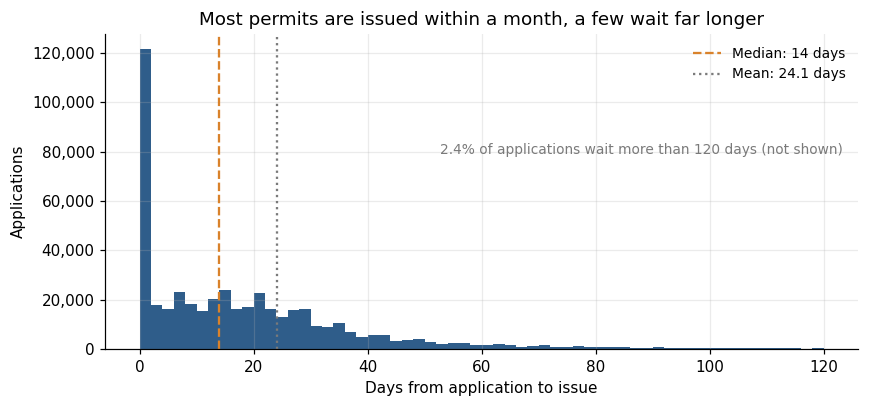

In [8]:
# Draw the distribution of the wait, limited to 120 days so the main shape is visible
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(wait[wait <= 120], bins=np.arange(0, 122, 2), color=BLUE)
ax.axvline(wait.median(), color=ORANGE, ls="--", label=f"Median: {wait.median():.0f} days")
ax.axvline(wait.mean(), color=GREY, ls=":", label=f"Mean: {wait.mean():.1f} days")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set(xlabel="Days from application to issue", ylabel="Applications",
       title="Most permits are issued within a month, a few wait far longer")
ax.legend(frameon=False, fontsize=9)
ax.text(0.98, 0.62, f"{(wait > 120).mean():.1%} of applications wait more than 120 days (not shown)",
        transform=ax.transAxes, ha="right", color=GREY, fontsize=9)
plt.tight_layout()
plt.show()

The typical application is issued in 14 days, and three out of four are issued within 28 days. About one in five (21.7%) is issued on the same day as the application, which explains the tall first bar.

The tail is long. One application in ten waits 49 days or more, one in a hundred waits more than 204 days, and the longest wait is 4,684 days. These cases pull the mean up to 24 days, ten days above the median, so the median is the better description of what an applicant should expect.

## 1.3 How the wait changed

The wait is compared across three periods: before 2017, 2017 to 2020 and 2021 to 2026. The limits were chosen after looking at the yearly pattern, so the comparison describes the data and does not test a hypothesis.

In [9]:
# Keep applications with a measurable wait and assign each one to a period
issued = df[df["days_to_issue"].notna()].copy()
issued["period"] = pd.cut(issued["application_year"], bins=[1998, 2016, 2020, 2026],
                          labels=["Before 2017", "2017 to 2020", "2021 to 2026"])
issued["same_day"] = issued["issued_same_day"].astype(float)

# Summarize the wait in each period
by_period = issued.groupby("period", observed=True).agg(
    applications=("days_to_issue", "size"),
    median_days=("days_to_issue", "median"),
    p90_days=("days_to_issue", lambda s: s.quantile(0.90)),
    same_day_share=("same_day", "mean"),
)
by_period.style.format({"applications": "{:,.0f}", "median_days": "{:.0f}",
                        "p90_days": "{:.0f}", "same_day_share": "{:.1%}"})

,applications,median_days,p90_days,same_day_share
period,,,,
Before 2017,"292,631",14,42,31.8%
2017 to 2020,"67,652",7,38,16.4%
2021 to 2026,"124,441",19,72,1.0%


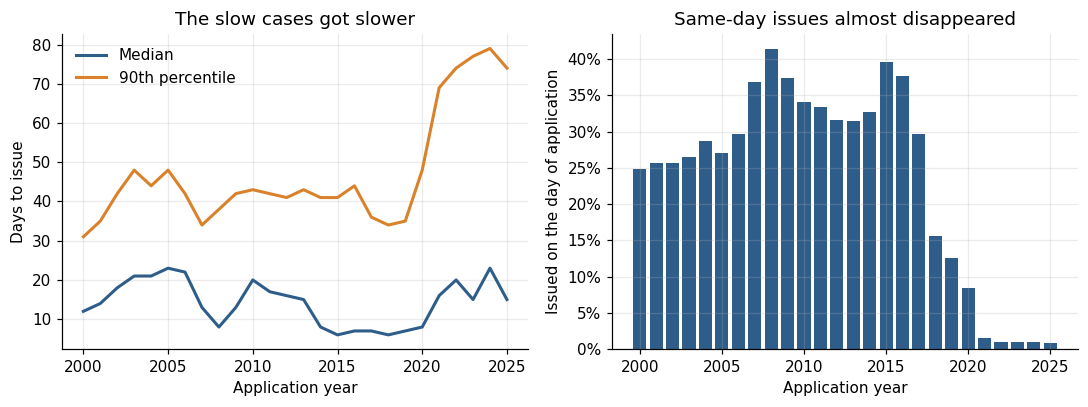

In [10]:
# Compute the yearly median, 90th percentile and same-day share, using complete years only
yearly = (issued[issued["full_year"]]
          .groupby("application_year")
          .agg(median=("days_to_issue", "median"),
               p90=("days_to_issue", lambda s: s.quantile(0.90)),
               same_day=("same_day", "mean")))

# Draw the wait by year next to the share of same-day issues
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.8))
a.plot(yearly.index, yearly["median"], color=BLUE, lw=2, label="Median")
a.plot(yearly.index, yearly["p90"], color=ORANGE, lw=2, label="90th percentile")
a.set(title="The slow cases got slower", xlabel="Application year", ylabel="Days to issue")
a.legend(frameon=False)
b.bar(yearly.index, yearly["same_day"], color=BLUE)
b.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
b.set(title="Same-day issues almost disappeared", xlabel="Application year",
      ylabel="Issued on the day of application")
plt.tight_layout()
plt.show()

The process changed twice. Between 2017 and 2020 the median wait fell from 14 to 7 days, while the share of same-day issues dropped from 31.8% to 16.4%. From 2021 the same-day route almost disappeared (1.0%), the median rose to 19 days and the 90th percentile went from 42 to 72 days.

The typical wait in 2021 to 2026 is longer than before, and the slow cases are much slower. The most recent applications may look faster than they are, because those still waiting have no issue date yet. Section 1.5 addresses this.

## 1.4 Who waits longest

The wait is compared across permit types in each period. Groups with fewer than 30 issued applications in a period are left out, because a median based on a handful of cases says little. This removes Environmental Restoration, which has only 10 issued applications in 2017 to 2020 and 1 from 2021.

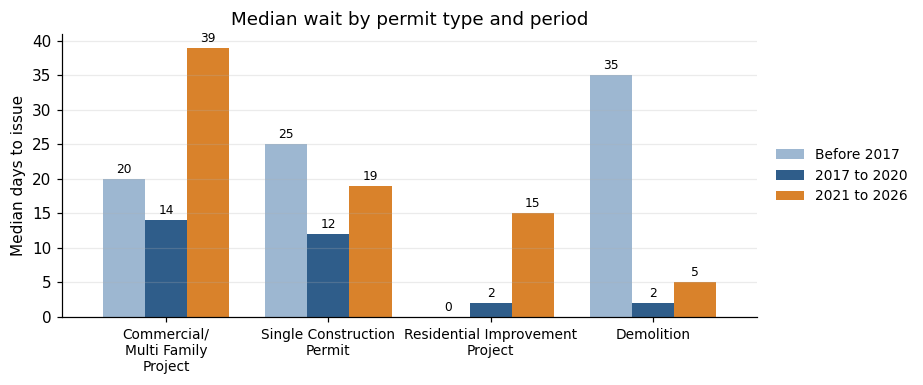

In [11]:
# Compute the median wait by permit type and period, keeping groups with at least 30 applications
MIN_N = 30
groups = (issued.groupby(["permittype", "period"], observed=True)["days_to_issue"]
          .agg(n="size", median="median").reset_index())
groups = groups[groups["n"] >= MIN_N]
medians = groups.pivot(index="permittype", columns="period", values="median").dropna()
medians = medians.loc[medians["2021 to 2026"].sort_values(ascending=False).index]

# Break long labels over two lines so they fit under the bars
medians.index = [t.replace(" / ", "/\n").replace(" Project", "\nProject").replace(" Permit", "\nPermit")
                 for t in medians.index]

# Draw the median wait for each permit type in the three periods
fig, ax = plt.subplots(figsize=(8.5, 3.6))
medians.plot.bar(ax=ax, color=[LIGHT_BLUE, BLUE, ORANGE], width=0.78, rot=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", fontsize=8, padding=2)
ax.set(xlabel="", ylabel="Median days to issue", title="Median wait by permit type and period")
ax.grid(axis="x", visible=False)
ax.legend(title=None, frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9)
ax.tick_params(axis="x", labelsize=9)
plt.tight_layout()
plt.show()

The wait depends on the type of permit, and the change from 2021 is not the same everywhere. In 2021 to 2026 Commercial/Multi Family projects wait the longest (median 39 days, about twice the 20 of the years before 2017), followed by Single Construction permits (19 days), Residential Improvement projects (15) and Demolition (5). Compared with 2017 to 2020 the median rose in every type. Compared with the years before 2017 it rose for Commercial/Multi Family (20 to 39) and for Residential Improvement (0 to 15), where more than half of the applications used to be issued on the same day, and it fell for Single Construction (25 to 19) and for Demolition (35 to 5). The rise since 2021 is therefore not a single trend: it affects the types differently.

## 1.5 Applications that never finish

Every application ends in one of three ways: it is issued, it ends without a permit (cancelled or refused), or it is still waiting at the snapshot date. For the last group the final outcome is not known yet, so leaving them out would make the process look faster than it is.

The next cell assigns each application its outcome and the number of days observed. For issued applications this is the wait. For those that ended without a permit it is the time to the end date. For those still waiting it is the time up to the snapshot date, 2026-11-05. Applications with missing or inconsistent dates (307) are not usable.

In [12]:
# Assign the outcome (1 issued, 2 ended without issue, 0 still waiting) and the days observed
SNAPSHOT = pd.Timestamp("2026-11-05")
outcome = pd.Series(np.nan, index=df.index)
followup = pd.Series(np.nan, index=df.index)

has_issue = df["days_to_issue"].notna()
outcome[has_issue] = 1
followup[has_issue] = df["days_to_issue"]

days_to_end = (df["completeddate"] - df["applieddate"]).dt.days
ended = (df["status_group"] == "Cancelled or refused") & ~has_issue & (days_to_end >= 0)
outcome[ended] = 2
followup[ended] = days_to_end

waiting = df["status_group"].isin(["Open before issue", "On hold"]) & ~has_issue
outcome[waiting] = 0
followup[waiting] = (SNAPSHOT - df["applieddate"]).dt.days

# Count the applications in each outcome
names = {1: "Issued", 2: "Ended without issue", 0: "Still waiting"}
outcome.map(names).fillna("Not usable").value_counts().to_frame("applications")

,applications
Issued,484724
Ended without issue,13168
Still waiting,5212
Not usable,307


Of the 503,411 applications, 484,724 were issued, 13,168 ended without a permit, 5,212 are still waiting and 307 are not usable. The 13,168 are 14 fewer than the 13,182 of section 1.1 because 14 applications that ended without issue have no valid end date, and those 14 are added to the 293 applications of section 1.1 whose status should have an issue date, which makes the 307.

In [13]:
# Estimate the share issued and the share ended without issue by day
def cumulative_incidence(days, outcome):
    days = days.astype(int).to_numpy()
    outcome = outcome.astype(int).to_numpy()
    size = days.max() + 1
    issued = np.bincount(days[outcome == 1], minlength=size)
    ended = np.bincount(days[outcome == 2], minlength=size)
    leaving = np.bincount(days, minlength=size)
    at_risk = len(days) - np.concatenate([[0], np.cumsum(leaving)[:-1]])
    h_issued, h_ended = issued / at_risk, ended / at_risk
    still_here = np.concatenate([[1], np.cumprod(1 - h_issued - h_ended)[:-1]])
    simple = 1 - np.cumprod(1 - h_issued)
    return pd.DataFrame({"issued": np.cumsum(still_here * h_issued),
                         "ended": np.cumsum(still_here * h_ended),
                         "simple_estimate": simple})

# Apply it to the usable applications and read the curves at 30, 90, 180 and 365 days
usable = outcome.notna()
curves = cumulative_incidence(followup[usable], outcome[usable])
curves.loc[[30, 90, 180, 365]].round(3)

,issued,ended,simple_estimate
30,0.755,0.013,0.763
90,0.930,0.017,0.944
180,0.956,0.020,0.972
365,0.966,0.023,0.984


Three out of four applications (75.5%) are issued within 30 days, 93.0% within 90 days and 96.6% within a year. Another 2.3% end without a permit within the year, and the rest are still open.

The simple estimate puts the share issued within a year at 98.4%. That is 1.8 points too high, because it assumes that the cancelled and refused applications could still have been issued. The difference looks small, but it is of the same order as the 2.3% of applicants who end without a permit.

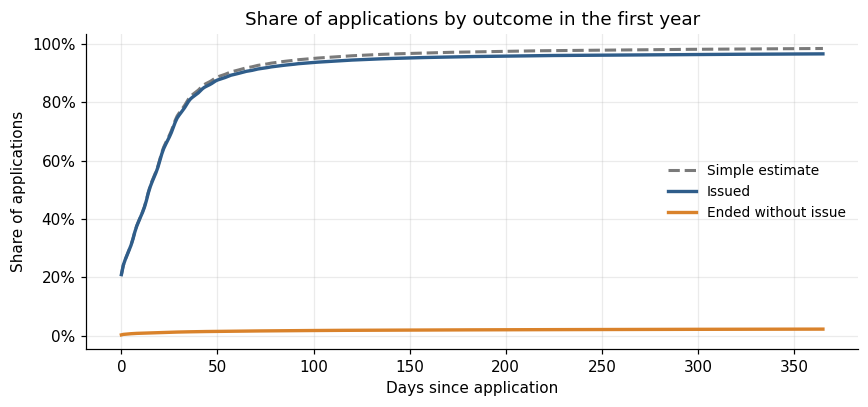

In [14]:
# Draw the three curves for the first year
first_year = curves.loc[0:365]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(first_year["simple_estimate"], color=GREY, ls="--", lw=2, label="Simple estimate")
ax.plot(first_year["issued"], color=BLUE, lw=2.2, label="Issued")
ax.plot(first_year["ended"], color=ORANGE, lw=2.2, label="Ended without issue")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set(xlabel="Days since application", ylabel="Share of applications",
       title="Share of applications by outcome in the first year")
ax.legend(frameon=False, loc="center right", fontsize=9)
plt.tight_layout()
plt.show()

The blue line climbs steeply in the first 50 days, from about 21% issued on day 0 to nearly 90%, and then flattens: after the first quarter, waiting longer adds little. The dashed grey line follows the blue one at first and then drifts above it, which is the overstatement of the simple estimate. The orange line grows slowly and stays near 2%, the share of applications that end without a permit.

**Summary of Chapter 1: The wait**

**Question:** How long does it take to receive a permit, and has that changed?

**Answer:** A typical application is issued in 14 days, and three out of four within 28. Within a year, 96.6% are issued and 2.3% end without a permit. The wait has changed twice: it fell to a median of 7 days between 2017 and 2020, and it has risen to 19 days since 2021, when the same-day route almost disappeared and the 90th percentile went from 42 to 72 days.

**What the evidence shows:**

* The median describes the experience of an applicant better than the average, 14 days against 24, because a few very slow applications pull the average up.
* The slow cases are where the process changed most: the 90th percentile rose by 30 days, while the median changed by 5 days.
* Commercial and multi-family projects are now the slowest permit type, with a median of 39 days since 2021, almost three times the 2017 to 2020 level.
* A success rate that ignores the applications that end without a permit is 1.8 points too high, 98.4% instead of 96.6%.

# Chapter 2. The money

**Question:** How large are the projects, and what separates the small from the very large?

**Why it matters:** Cost shapes the workload, the fees and the risk of a permit office, and it is the variable that a few giant projects distort the most.

## 2.1 What is measured

The estimated project cost is declared by the applicant, so it is an estimate and not a final cost. Costs that are missing, negative or below 10 dollars are set to missing in the cleaned column, and the original column is kept next to it. The first step is to see which applications have a usable cost.

In [15]:
# Count the applications with a usable cost, by permit type
coverage = (df.assign(with_cost=df["estprojectcost_clean"].notna())
              .groupby("permittype")["with_cost"]
              .agg(applications="size", with_cost="sum"))
coverage["share_with_cost"] = coverage["with_cost"] / coverage["applications"]
coverage = coverage.sort_values("applications", ascending=False)

# Show the table and the overall total
print(f"All applications: {len(df):,}, with a usable cost: {df['estprojectcost_clean'].notna().sum():,} "
      f"({df['estprojectcost_clean'].notna().mean():.1%})")
coverage.style.format({"applications": "{:,.0f}", "with_cost": "{:,.0f}", "share_with_cost": "{:.1%}"})

All applications: 503,411, with a usable cost: 463,801 (92.1%)


,applications,with_cost,share_with_cost
permittype,,,
Residential Improvement Project,"227,072","212,924",93.8%
Single Construction Permit,"156,706","154,319",98.5%
Commercial / Multi Family Project,"101,181","95,957",94.8%
Demolition,"17,705",0,0.0%
Environmental Restoration Permit,747,601,80.5%


A usable cost exists for 463,801 of the 503,411 applications (92.1%). The 39,610 without one are costs not provided (39,092, which include all 17,705 demolitions, expected because a demolition has no construction value), below 10 dollars (510) or negative (8). Without demolitions, 95.5% of the applications have a cost.

The analysis below uses the 463,801 projects with a cost, so every result describes projects with a declared estimate.

## 2.2 The typical project

Percentiles show what a typical project costs and how far the largest ones are from it. The histogram uses a log scale, where each step to the right is a tenfold increase, because costs range from a few dollars to hundreds of millions.

In [16]:
# Summarize the cost with the mean and percentiles
cost = df["estprojectcost_clean"].dropna()
cost_summary = pd.Series({
    "Mean": cost.mean(),
    "25th percentile": cost.quantile(0.25),
    "Median": cost.median(),
    "75th percentile": cost.quantile(0.75),
    "90th percentile": cost.quantile(0.90),
    "99th percentile": cost.quantile(0.99),
    "Largest project": cost.max(),
})
cost_summary.round(0).to_frame("dollars").style.format("{:,.0f}")

,dollars
Mean,"273,874"
25th percentile,"15,798"
Median,"55,549"
75th percentile,"200,000"
90th percentile,"370,624"
99th percentile,"2,353,051"
Largest project,"868,255,213"


The median project has an estimated cost of 55,549 dollars. Half of the projects cost between 15,798 and 200,000 dollars, one in ten costs more than 370,000 dollars, and the largest is 868 million dollars. The mean, 273,874 dollars, is almost five times the median because a few very large projects pull it up.

The level of this median depends on amounts that repeat many times, which section 2.3 examines.

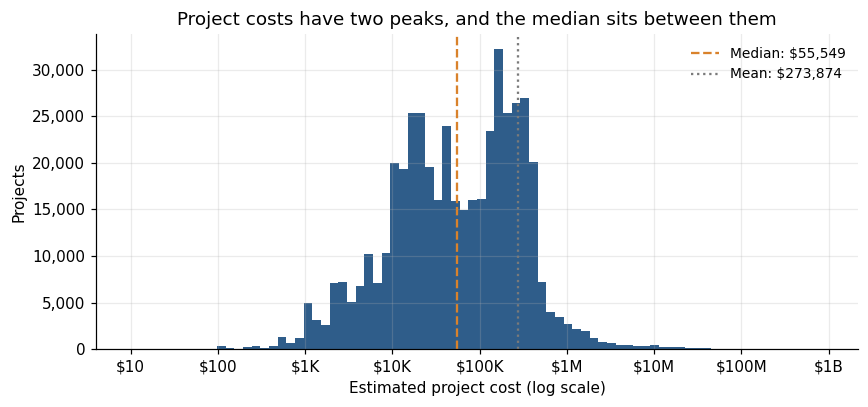

In [17]:
# Draw the distribution of the cost on a log scale, with the median and the mean
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(np.log10(cost), bins=80, color=BLUE)
ax.axvline(np.log10(cost.median()), color=ORANGE, ls="--", label=f"Median: ${cost.median():,.0f}")
ax.axvline(np.log10(cost.mean()), color=GREY, ls=":", label=f"Mean: ${cost.mean():,.0f}")

# Label the log axis with dollar amounts
ticks = [1e1, 1e2, 1e3, 1e4, 1e5, 1e6, 1e7, 1e8, 1e9]
ax.set_xticks(np.log10(ticks))
ax.set_xticklabels(["$10", "$100", "$1K", "$10K", "$100K", "$1M", "$10M", "$100M", "$1B"])
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set(xlabel="Estimated project cost (log scale)", ylabel="Projects",
       title="Project costs have two peaks, and the median sits between them")
ax.legend(frameon=False, loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

The chart shows why a single typical value is not enough. The costs form two groups, one around 20,000 dollars and a broader one between about 150,000 and 370,000 dollars, and the median falls in the dip between them, where fewer projects sit. The mean is at the upper end of the second group and describes almost no project. The following sections look at what separates the two groups.

## 2.3 How reliable is the typical cost

An estimated cost that appears again and again can be a standard amount instead of an estimate made project by project. The first check lists the 10 amounts that appear most often among the applications with a cost, with the most common type of permit for each one, and counts how many applications have an amount that appears at least 100 times. The second check recalculates the median and redraws the distribution of the previous section without those applications, to see whether the two groups of costs remain.

In [18]:
# Applications with a usable cost and the 10 amounts that appear most often
known = df[df["estprojectcost_clean"].notna()]
amounts = known["estprojectcost_clean"].value_counts().head(10)

# Table with the count, the share of the applications with a cost and the most common permit type
top_amounts = pd.DataFrame({"Applications": amounts,
                            "Share of costed (%)": amounts / len(known) * 100})
top_amounts["Most common type"] = [
    known.loc[known["estprojectcost_clean"] == a, "permitclassgroup"].mode()[0]
    for a in amounts.index
]
top_amounts = top_amounts.rename_axis("Amount ($)").reset_index()

# Applications whose amount appears at least 100 times
times_repeated = known["estprojectcost_clean"].map(known["estprojectcost_clean"].value_counts())
repeated = times_repeated >= 100
print(f"Applications with an amount that appears at least 100 times: "
      f"{repeated.sum():,} ({repeated.mean() * 100:.1f}% of those with a cost)")

top_amounts.style.format({"Amount ($)": "{:,.2f}", "Applications": "{:,.0f}",
                          "Share of costed (%)": "{:.2f}"})

Applications with an amount that appears at least 100 times: 132,457 (28.6% of those with a cost)


,Amount ($),Applications,Share of costed (%),Most common type
0,"10,000.00","4,152",0.90,Commercial
1,"5,000.00","3,963",0.85,Single Family
2,"38,576.00","3,730",0.80,Garage
3,"20,000.00","3,663",0.79,Commercial
4,"1,000.00","3,521",0.76,Single Family
5,"42,433.60","3,520",0.76,Garage
6,"50,000.00","3,174",0.68,Commercial
7,"15,000.00","3,055",0.66,Commercial
8,"30,000.00","3,040",0.66,Commercial
9,"2,000.00","2,866",0.62,Single Family


The costs are far less varied than they should be if each one were an independent estimate. 132,457 applications (28.6% of those with a cost) have an amount that appears at least 100 times. The 10 most frequent amounts appear between 2,866 and 4,152 times each and cover 34,684 applications, 7.5% of those with a cost.

Eight of the ten are round figures: 1,000, 2,000, 5,000, 10,000, 15,000, 20,000, 30,000 and 50,000 dollars, with Commercial as the most common type for five of them and Single Family for three. The other two are not round and belong to garage permits: 38,576.00 appears 3,730 times and 42,433.60 appears 3,520 times, 7,250 applications in total. An amount with cents repeated thousands of times is more likely a standard figure than an estimate made for each project. The dataset does not say why.

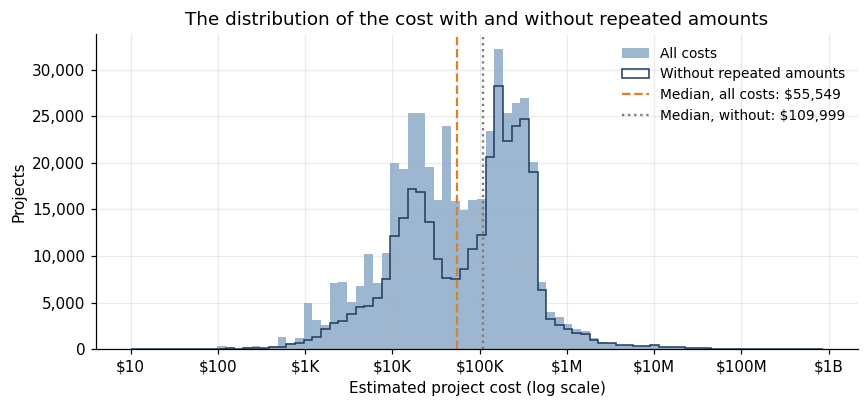

Removed from the cost: 132,457 of 463,801


In [19]:
# Costs: all applications with a cost, and the same without the amounts that appear at least 100 times
cost_all = df["estprojectcost_clean"].dropna()
cost_clean = cost_all[cost_all.map(cost_all.value_counts()) < 100]

# Draw both distributions on a log scale, with the same bins, and the median of each
bins = np.linspace(np.log10(cost_all.min()), np.log10(cost_all.max()), 81)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(np.log10(cost_all), bins=bins, color=LIGHT_BLUE, label="All costs")
ax.hist(np.log10(cost_clean), bins=bins, histtype="step", color=NAVY, lw=1.6, label="Without repeated amounts")
ax.axvline(np.log10(cost_all.median()), color=ORANGE, ls="--", label=f"Median, all costs: ${cost_all.median():,.0f}")
ax.axvline(np.log10(cost_clean.median()), color=GREY, ls=":", label=f"Median, without: ${cost_clean.median():,.0f}")

# Label the log axis with dollar amounts and place the legend on the right
ticks = [1e1, 1e2, 1e3, 1e4, 1e5, 1e6, 1e7, 1e8, 1e9]
ax.set_xticks(np.log10(ticks))
ax.set_xticklabels(["$10", "$100", "$1K", "$10K", "$100K", "$1M", "$10M", "$100M", "$1B"])
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set(xlabel="Estimated project cost (log scale)", ylabel="Projects",
       title="The distribution of the cost with and without repeated amounts")
ax.legend(frameon=False, loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

# Number of records removed
print(f"Removed from the cost: {len(cost_all) - len(cost_clean):,} of {len(cost_all):,}")

The two groups of costs remain without the repeated amounts, so they are not an effect of the standard amounts. The repeated amounts do change the picture in two ways. They create narrow spikes, such as the ones near 40,000 dollars where the two garage amounts fall, and the lower group loses more projects than the upper one when they are removed (42% of the projects below 70,000 dollars, against 14% of those above). As a result the dip between the groups is deeper without them, and the median moves from 55,549 dollars, inside the dip, to 109,999 at the start of the upper group.

The level of the median, and any comparison built on it, should be read as a property of the declared amounts, not as a precise measure of what projects cost.

## 2.4 What separates small from large

The two groups of costs suggest that the projects belong to different kinds of work. The permit class group shows which. The table and the chart cover the ten largest groups, which hold 98.2% of the projects. For each group the chart shows the middle half of its projects (from the 25th to the 75th percentile), the median and the 90th percentile.

In [20]:
# Summarize the cost by permit class group and keep the ten largest groups
has_cost = df[df["estprojectcost_clean"].notna()]
by_group = has_cost.groupby("permitclassgroup")["estprojectcost_clean"].agg(
    projects="size",
    p25=lambda s: s.quantile(0.25),
    median="median",
    p75=lambda s: s.quantile(0.75),
    p90=lambda s: s.quantile(0.90),
)
top = by_group.sort_values("projects", ascending=False).head(10)

# Show the table and the share of projects the ten groups cover
print(f"The ten largest groups hold {top['projects'].sum() / len(has_cost):.1%} of the projects")
top.style.format("{:,.0f}")

The ten largest groups hold 98.2% of the projects


,projects,p25,median,p75,p90
permitclassgroup,,,,,
Single Family,"254,185","15,198","100,000","244,776","363,910"
Garage,"62,445","13,572","19,921","38,576","46,677"
Commercial,"59,034","24,000","73,672","208,000","700,000"
Two Family,"27,522","104,765","173,313","207,526","251,208"
Secondary Suites,"17,314","15,000","56,764","69,864","82,964"
Townhouse,"10,519","14,704","410,202","1,077,078","1,612,580"
Institutional,"8,966","25,000","98,000","325,000","1,166,027"
Apartment,"6,570","15,002","110,000","1,088,090","10,937,119"
Industrial,"5,206","25,000","70,000","250,000","1,257,318"


Garages are the clearest case of the small group: their median is 19,921 dollars and three out of four cost less than 38,576, the same standard amount that section 2.3 lists among the most repeated. Single family projects cover both groups: a quarter of them cost less than 15,198 dollars, while the median is 100,000. Townhouses have the highest median of all, 410,202 dollars.

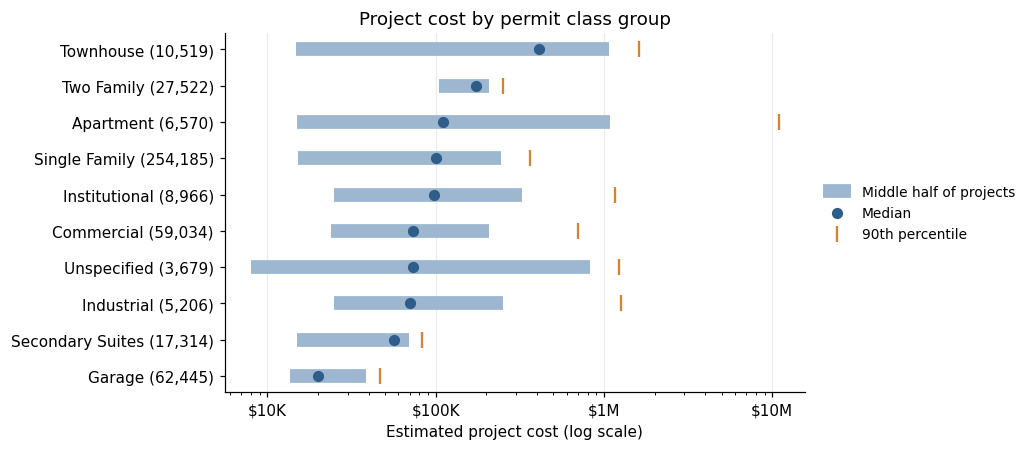

In [21]:
# Order the groups by median cost and draw the middle half, the median and the 90th percentile
top = top.sort_values("median")
fig, ax = plt.subplots(figsize=(9.5, 4.2))
y = np.arange(len(top))
ax.hlines(y, top["p25"], top["p75"], color=LIGHT_BLUE, lw=9, label="Middle half of projects")
ax.scatter(top["median"], y, color=BLUE, zorder=3, s=40, label="Median")
ax.scatter(top["p90"], y, color=ORANGE, marker="|", s=120, zorder=3, label="90th percentile")

# Use a log scale and show the number of projects next to each group name
ax.set_xscale("log")
ax.set_yticks(y)
ax.set_yticklabels([f"{g} ({n:,.0f})" for g, n in zip(top.index, top["projects"])])
ax.xaxis.set_major_formatter(plt.FuncFormatter(
    lambda v, _: "$" + (f"{v/1e6:g}M" if v >= 1e6 else f"{v/1e3:g}K" if v >= 1e3 else f"{v:g}")))
ax.set(xlabel="Estimated project cost (log scale)", ylabel="", title="Project cost by permit class group")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9)
plt.tight_layout()
plt.show()

The chart shows that the spread inside a group can be wider than the gap between groups. Half of the apartment projects fall between 15,002 and 1.09 million dollars (the long light bar), and one in ten costs more than 10.9 million (the orange mark far to the right). Garages and two-family projects have short bars, so their costs are more predictable. A single cost figure for the whole city hides these differences, and so does a single figure for most groups.

## 2.5 Where the money is concentrated

A permit office counts projects, but the value they represent is very unevenly spread. The next step ranks all projects by cost and asks how much of the total estimated value the largest ones hold.

In [22]:
# Rank the projects by cost and measure the share of the total value held by each group
ranked = cost.sort_values(ascending=False).to_numpy()
total_value = ranked.sum()
n_projects = len(ranked)

def value_share(fraction, largest=True):
    k = int(n_projects * fraction)
    part = ranked[:k] if largest else ranked[n_projects - k:]
    return len(part), part.sum() / total_value

shares = pd.DataFrame(
    [("Largest 0.1%", *value_share(0.001)), ("Largest 1%", *value_share(0.01)),
     ("Largest 10%", *value_share(0.10)), ("Smallest 50%", *value_share(0.50, largest=False))],
    columns=["group", "projects", "share_of_value"]).set_index("group")

# Show the total value and the shares
print(f"Total estimated value: ${total_value / 1e9:,.1f} billion in {n_projects:,} projects")
shares.style.format({"projects": "{:,.0f}", "share_of_value": "{:.1%}"})

Total estimated value: $127.0 billion in 463,801 projects


,projects,share_of_value
group,,
Largest 0.1%,463,23.0%
Largest 1%,"4,638",47.6%
Largest 10%,"46,380",69.8%
Smallest 50%,"231,900",3.5%


The 463 largest projects (0.1% of the projects) hold 23.0% of the 127.0 billion dollars of estimated value. The largest 1% hold 47.6% and the largest 10% hold 69.8%, while the cheaper half of the projects, 231,900 of them, hold only 3.5%.

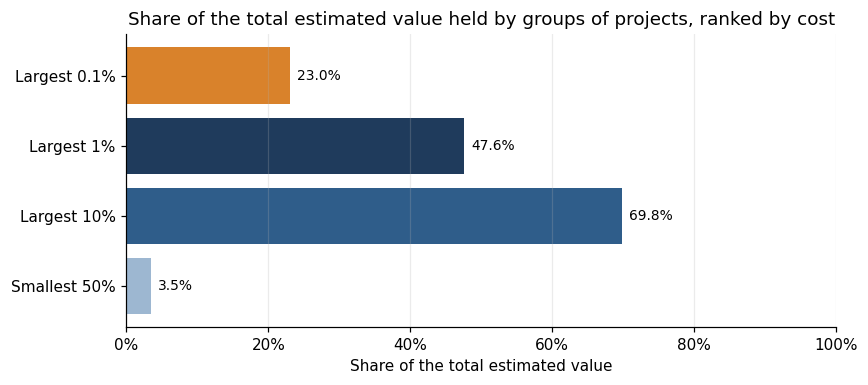

In [23]:
# Draw the share of the total value held by each group of projects
order = ["Smallest 50%", "Largest 10%", "Largest 1%", "Largest 0.1%"]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(order, shares.loc[order, "share_of_value"], color=[LIGHT_BLUE, BLUE, NAVY, ORANGE])
for i, v in enumerate(shares.loc[order, "share_of_value"]):
    ax.text(v + 0.01, i, f"{v:.1%}", va="center", fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set(xlim=(0, 1), xlabel="Share of the total estimated value",
       title="Share of the total estimated value held by groups of projects, ranked by cost")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Each bar answers the same question: if all projects are ranked by cost, how much of the total estimated value do the projects in this group hold? The groups are nested, so the largest 0.1% is part of the largest 1%, which is part of the largest 10%. At the two ends, the 463 largest projects hold more than six times the value of the 231,900 cheapest ones.

Counting permits and counting value therefore tell different stories. The ten largest projects are worth between 315 and 868 million dollars each, so a decision about a handful of large projects can move the total more than thousands of small ones.

Section 2.3 showed that many costs are standard amounts that repeat. The concentration is recalculated without the amounts that appear at least 100 times, to see whether those amounts distort it.

In [24]:
# Share of the total value held by the largest projects, as reported and without repeated amounts
def share_of_value(c, fraction):
    k = int(len(c) * fraction)
    return c.nlargest(k).sum() / c.sum() * 100

fractions = {"Largest 0.1%": 0.001, "Largest 1%": 0.01, "Largest 10%": 0.10}
concentration_check = pd.DataFrame({
    "As reported (%)": {g: share_of_value(cost_all, f) for g, f in fractions.items()},
    "Without repeated amounts (%)": {g: share_of_value(cost_clean, f) for g, f in fractions.items()},
}).round(1)

# Change in percentage points, calculated from the rounded values shown in the table
concentration_check["Change (points)"] = (concentration_check["Without repeated amounts (%)"]
                                          - concentration_check["As reported (%)"])
concentration_check.style.format("{:,.1f}")

,As reported (%),Without repeated amounts (%),Change (points)
Largest 0.1%,23.0,21.9,-1.1
Largest 1%,47.6,48.6,1.0
Largest 10%,69.8,69.7,-0.1


The concentration does not depend on the repeated amounts. Without them, the largest 0.1% of the projects holds 21.9% of the total value (23.0% as reported), the largest 1% holds 48.6% (47.6%) and the largest 10% holds 69.7% (69.8%). The largest 1% and 10% hardly move, and the largest 0.1% loses about one point. A few very large projects hold a large part of the value whether or not the standard amounts are counted.

## 2.6 Cost over time

The median cost of all projects is followed year by year, using complete years only. A sharp change in a median can mean that costs changed, or that the mix of projects did. The check is to look inside one large group, single family, which contains two kinds of work: improvements of existing houses and new construction.

In [25]:
# Compute the yearly median cost, the share of projects below 50,000 dollars and the share of new construction in single family
complete = has_cost[has_cost["full_year"]]
yearly = complete.groupby("application_year")["estprojectcost_clean"].agg(
    median="median", share_below_50k=lambda s: (s < 50000).mean())
single_family = complete[complete["permitclassgroup"] == "Single Family"]
yearly["single_family_new_share"] = (single_family.groupby("application_year")["workclassgroup"]
                                     .apply(lambda s: (s == "New").mean()))

# Show selected years around the drop
yearly.loc[[2005, 2006, 2007, 2008, 2012, 2025]].style.format(
    {"median": "{:,.0f}", "share_below_50k": "{:.1%}", "single_family_new_share": "{:.1%}"})

,median,share_below_50k,single_family_new_share
application_year,,,
2005,"97,571",41.2%,67.0%
2006,"81,836",45.7%,63.6%
2007,"24,267",53.6%,52.2%
2008,"22,000",59.4%,39.3%
2012,"40,224",51.1%,50.0%
2025,"69,864",37.0%,49.7%


The median cost of all projects falls from 81,836 dollars in 2006 to 24,267 in 2007, a drop of 70% in one year. At the same time, the share of projects below 50,000 dollars goes from 45.7% to 53.6%, so it crosses one half. With two groups of costs in the data, the median jumps from one group to the other when that share crosses 50%.

Inside single family, new construction falls from 63.6% of the projects in 2006 to 39.3% in 2008, and the improvements take its place.

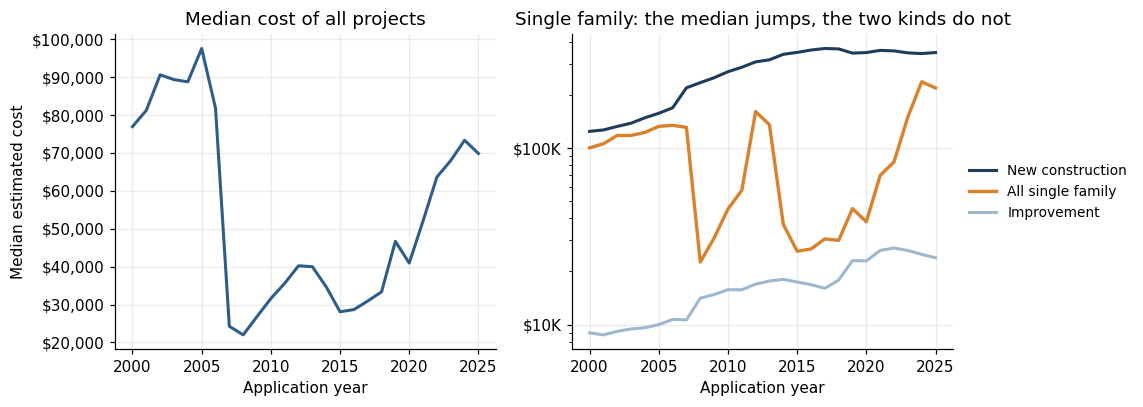

In [26]:
# Compute the yearly median of single family projects, in total and by kind of work
single_family_median = single_family.groupby("application_year")["estprojectcost_clean"].median()
by_kind = (single_family.groupby(["application_year", "workclassgroup"])["estprojectcost_clean"]
           .median().unstack())

# Draw the median of all projects next to the single family medians
fig, (a, b) = plt.subplots(1, 2, figsize=(10.5, 3.8))
a.plot(yearly.index, yearly["median"], color=BLUE, lw=2)
a.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
a.set(title="Median cost of all projects", xlabel="Application year", ylabel="Median estimated cost")

b.plot(by_kind.index, by_kind["New"], color=NAVY, lw=2, label="New construction")
b.plot(single_family_median.index, single_family_median, color=ORANGE, lw=2.2, label="All single family")
b.plot(by_kind.index, by_kind["Improvement"], color=LIGHT_BLUE, lw=2, label="Improvement")
b.set_yscale("log")
b.set_yticks([1e4, 1e5])
b.set_yticklabels(["$10K", "$100K"])
b.set(title="Single family: the median jumps, the two kinds do not", xlabel="Application year")
b.legend(frameon=False, fontsize=9, loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.show()

The left chart shows the drop of 2007 and a recovery that is fast after 2020, from about 41,000 dollars to about 73,000 in 2024. The right chart looks inside single family, where the median of new construction (dark blue) and the median of improvements (light blue) rise steadily. The median of the whole group (orange) falls from 131,047 dollars in 2007 to 22,608 in 2008, rises again, and swings a second time between 2013 and 2015. It does so because it follows whichever kind of work is more frequent that year.

The fall of 2008 in single family is therefore a change in the mix of work, not cheaper projects. A median over time is only safe to read when the mix is stable or the kinds of work are separated. The drop of the overall median in 2007 comes one year earlier and is examined in the last check of this section.

The sharp fall of 2007 is not explained by the mix of single family projects. One more check is whether the repeated amounts of section 2.3 changed over the years and moved the median. The yearly median is recalculated without the amounts that appear at least 100 times, and the table shows the share of repeated amounts in each year.

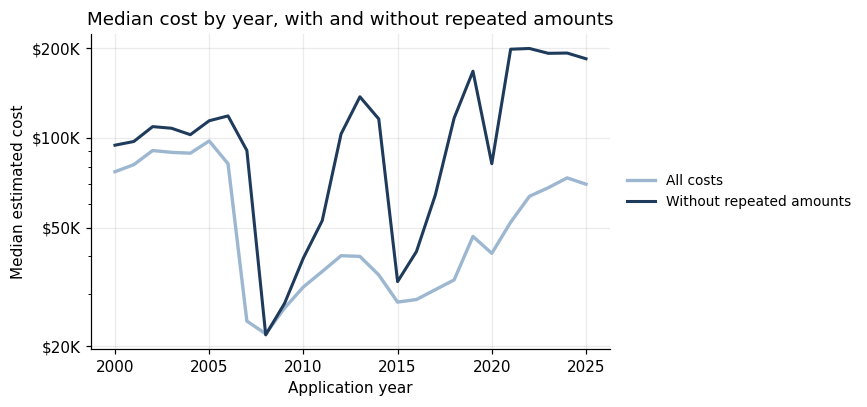

,"Median, all costs","Median, without repeated",Repeated amounts (%)
application_year,,,
2005,"97,571","114,061",16.1
2006,"81,836","118,407",21.2
2007,"24,267","90,657",22.7
2008,"22,000","21,819",19.6
2012,"40,224","103,000",21.5
2025,"69,864","184,129",38.3


In [27]:
# Number of times each amount appears among all the costs, used to mark the repeated amounts
repeat_count = df["estprojectcost_clean"].map(cost_all.value_counts())

# Yearly median in complete years, as reported and without the repeated amounts
full = df[df["estprojectcost_clean"].notna() & df["full_year"]]
median_all = full.groupby("application_year")["estprojectcost_clean"].median()
median_clean = (full[repeat_count[full.index] < 100]
                .groupby("application_year")["estprojectcost_clean"].median())
repeated_share = ((repeat_count[full.index] >= 100)
                  .groupby(full["application_year"]).mean() * 100)

# Draw both yearly medians on a log scale
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(median_all, color=LIGHT_BLUE, lw=2.2, label="All costs")
ax.plot(median_clean, color=NAVY, lw=2, label="Without repeated amounts")
ax.set_yscale("log")
ax.set_yticks([2e4, 5e4, 1e5, 2e5])
ax.set_yticklabels(["$20K", "$50K", "$100K", "$200K"])
ax.yaxis.set_minor_formatter(mtick.NullFormatter())
ax.set(title="Median cost by year, with and without repeated amounts",
       xlabel="Application year", ylabel="Median estimated cost")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9)
plt.tight_layout()
plt.show()

# Show selected years around the drop, with the share of repeated amounts
pd.DataFrame({"Median, all costs": median_all,
              "Median, without repeated": median_clean,
              "Repeated amounts (%)": repeated_share}).loc[[2005, 2006, 2007, 2008, 2012, 2025]].style.format(
    {"Median, all costs": "{:,.0f}", "Median, without repeated": "{:,.0f}", "Repeated amounts (%)": "{:.1f}"})

Without the repeated amounts the median does not fall in 2007: it goes from 118,407 dollars in 2006 to 90,657 in 2007, and it only falls in 2008, to 21,819, the same level as with all the costs (22,000). The drop of 2007 in the line with all costs therefore comes from the repeated amounts, which tip the median into the lower group of costs one year earlier. The drop of 2008 is there either way.

The two lines are far apart in most years, for example 40,224 against 103,000 dollars in 2012 and 69,864 against 184,129 in 2025. The median sits in the dip between the two groups of costs, so a small change in what fills the dip moves it from one group to the other. The share of repeated amounts also rises over time, from 16.1% of the costs in 2005 to 38.3% in 2025, because the two garage amounts of section 2.3 appear only from 2019. The yearly median is therefore a fragile measure, and its changes should be read together with the mix of work and the repeated amounts.

## 2.7 Cost in constant dollars

Costs from different years are not comparable in current dollars, because prices rise over time. The Consumer Price Index (CPI) for Calgary (all items, Statistics Canada, table 18-10-0005-01) is used to convert every cost to 2025 dollars.

Each application year gets a factor, the CPI of 2025 divided by the CPI of that year:

factor = CPI 2025 / CPI of the application year

Each cost is multiplied by the factor of its year. The factor is 1 for 2025 and larger for earlier years. For example, the factor of 2000 is about 1.86, so a median of 76,948 dollars in 2000 is equivalent to 143,347 dollars in 2025. The index measures consumer prices in general, so the result is an approximation for construction costs.

In [28]:
import io
import zipfile
import requests

In [29]:
# Download the annual Consumer Price Index table of Statistics Canada (zipped CSV)
url = "https://www150.statcan.gc.ca/n1/tbl/csv/18100005-eng.zip"
response = requests.get(url, timeout=300)
response.raise_for_status()
with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    name = [n for n in z.namelist() if n.endswith(".csv") and "MetaData" not in n][0]
    cpi_raw = pd.read_csv(z.open(name))

# Keep the all-items index for Calgary and build the factor to 2025 dollars for each year
cpi = cpi_raw[(cpi_raw["GEO"] == "Calgary, Alberta") & (cpi_raw["Products and product groups"] == "All-items")]
cpi = cpi.set_index("REF_DATE")["VALUE"]
cpi.index = cpi.index.astype(int)
cpi_factor = cpi.loc[2025] / cpi

# Check that every application year has an index
print("Years without index:", [y for y in range(1999, 2027) if y not in cpi.index])

Years without index: [2026]


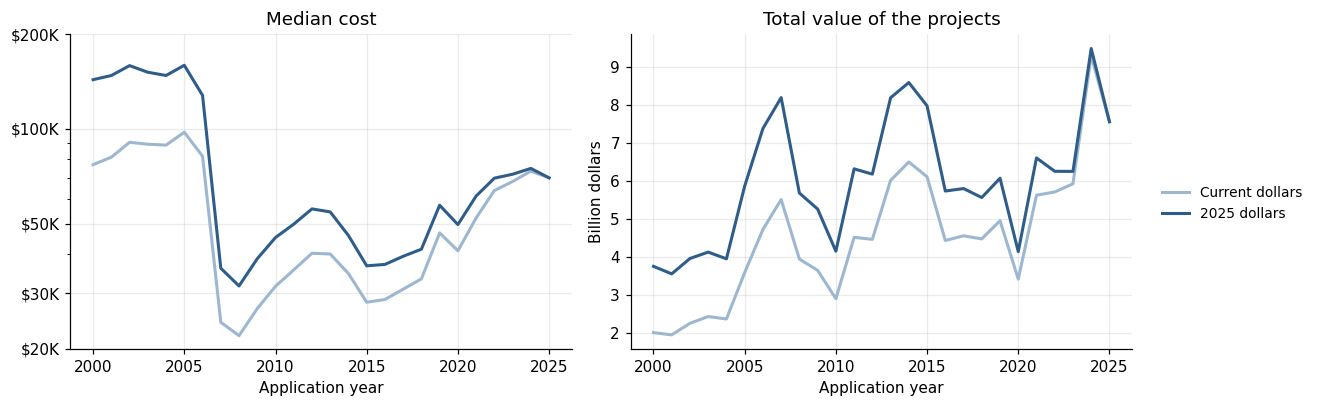

,projects,median current,median 2025,total current (billion),total 2025 (billion)
application_year,,,,,
2000,"12,920","76,948","143,347",2.0,3.8
2006,"19,750","81,836","127,746",4.7,7.4
2007,"17,562","24,267","36,051",5.5,8.2
2015,"15,423","28,104","36,684",6.1,8.0
2025,"21,332","69,864","69,864",7.6,7.6


In [30]:
# Convert each cost to 2025 dollars with the factor of its application year (complete years only)
real = complete.copy()
real["cost_2025"] = real["estprojectcost_clean"] * real["application_year"].astype(int).map(cpi_factor)

# Compute the median and the total value by year, in current dollars and in 2025 dollars
by_year_real = pd.DataFrame({
    "projects": real.groupby("application_year").size(),
    "median current": real.groupby("application_year")["estprojectcost_clean"].median(),
    "median 2025": real.groupby("application_year")["cost_2025"].median(),
    "total current (billion)": real.groupby("application_year")["estprojectcost_clean"].sum() / 1e9,
    "total 2025 (billion)": real.groupby("application_year")["cost_2025"].sum() / 1e9,
})

# Draw the median (log scale) and the total value, with one shared legend on the right
fig, (a, b) = plt.subplots(1, 2, figsize=(10.5, 3.8))
a.plot(by_year_real["median current"], color=LIGHT_BLUE, lw=2, label="Current dollars")
a.plot(by_year_real["median 2025"], color=BLUE, lw=2, label="2025 dollars")
a.set_yscale("log")
a.set_yticks([2e4, 3e4, 5e4, 1e5, 2e5])
a.set_yticklabels(["$20K", "$30K", "$50K", "$100K", "$200K"])
a.yaxis.set_minor_formatter(mtick.NullFormatter())
a.set(title="Median cost", xlabel="Application year")

b.plot(by_year_real["total current (billion)"], color=LIGHT_BLUE, lw=2)
b.plot(by_year_real["total 2025 (billion)"], color=BLUE, lw=2)
b.set(title="Total value of the projects", xlabel="Application year", ylabel="Billion dollars")

handles, labels = a.get_legend_handles_labels()
fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

# Show selected years
by_year_real.loc[[2000, 2006, 2007, 2015, 2025]].style.format({
    "projects": "{:,.0f}", "median current": "{:,.0f}", "median 2025": "{:,.0f}",
    "total current (billion)": "{:,.1f}", "total 2025 (billion)": "{:,.1f}"})

In 2025 dollars, the median cost falls from 143,347 dollars in 2000 to 69,864 in 2025, a drop of 51%. In the chart, the dark line (2025 dollars) starts far above the light line (declared amounts) and the two meet in 2025, because the factor there is 1. The sharp fall of 2007 remains after the adjustment (127,746 dollars in 2006 and 36,051 in 2007), so it is not an inflation effect.

The total value tells a different story. In 2025 dollars it doubles from 3.8 billion dollars in 2000 to 7.6 billion in 2025, while the number of projects with a cost rises from 12,920 in 2000 to 21,332 in 2025. The rise is not steady: the total peaks near 8.2 billion in 2007 and 8.6 in 2014, and the highest year is 2024, at about 9.5 billion. A few very large projects hold most of the value (section 2.5), so the total follows them and not the median.

The fall of 51% in the median may be affected by the repeated amounts of section 2.3, which become more common over the years. The median in 2025 dollars is recalculated without the amounts that appear at least 100 times.

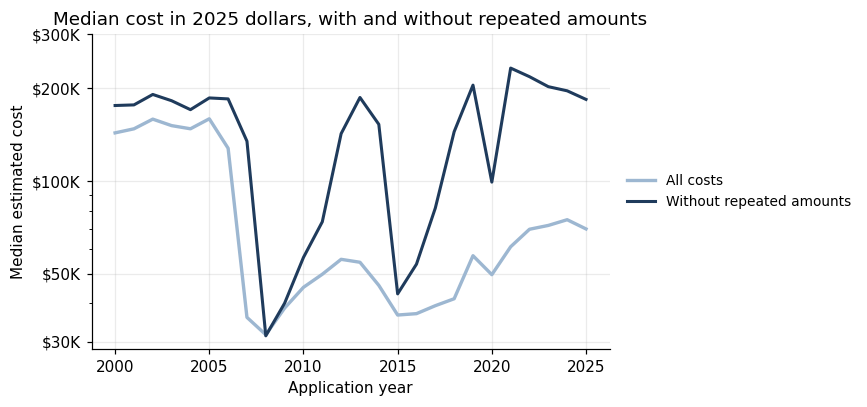

All costs: 143,347 dollars in 2000, 69,864 in 2025 (-51%)
Without repeated amounts: 175,912 dollars in 2000, 184,129 in 2025 (+5%)


,All costs,Without repeated amounts
application_year,,
2000,"143,347","175,912"
2006,"127,746","184,833"
2007,"36,051","134,680"
2008,"31,663","31,403"
2015,"36,684","42,980"
2025,"69,864","184,129"


In [31]:
# Median in 2025 dollars without the repeated amounts, in complete years
real_clean = real[repeat_count[real.index] < 100]
median_2025 = pd.DataFrame({
    "All costs": by_year_real["median 2025"],
    "Without repeated amounts": real_clean.groupby("application_year")["cost_2025"].median(),
})

# Draw both medians in 2025 dollars on a log scale
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(median_2025["All costs"], color=LIGHT_BLUE, lw=2.2, label="All costs")
ax.plot(median_2025["Without repeated amounts"], color=NAVY, lw=2, label="Without repeated amounts")
ax.set_yscale("log")
ax.set_yticks([3e4, 5e4, 1e5, 2e5, 3e5])
ax.set_yticklabels(["$30K", "$50K", "$100K", "$200K", "$300K"])
ax.yaxis.set_minor_formatter(mtick.NullFormatter())
ax.set(title="Median cost in 2025 dollars, with and without repeated amounts",
       xlabel="Application year", ylabel="Median estimated cost")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9)
plt.tight_layout()
plt.show()

# Change between 2000 and 2025 for each version, and selected years
for name in median_2025.columns:
    first, last = median_2025.loc[2000, name], median_2025.loc[2025, name]
    print(f"{name}: {first:,.0f} dollars in 2000, {last:,.0f} in 2025 ({last / first - 1:+.0%})")
median_2025.loc[[2000, 2006, 2007, 2008, 2015, 2025]].style.format("{:,.0f}")

The fall of 51% depends on the repeated amounts. Without them, the median in 2025 dollars goes from 175,912 dollars in 2000 to 184,129 in 2025 (+5%), so the data do not show a decline in the cost of a typical project. The two versions agree before 2006 and in 2008 (31,663 and 31,403), and they disagree most in 2007 (36,051 against 134,680) and in the last years, when the repeated amounts are most frequent.

Without the repeated amounts the median is not stable either. It falls to about 31,000 dollars in 2008, 43,000 in 2015 and 100,000 in 2020, and then returns to between 180,000 and 230,000. This is the same pattern as in section 2.6: the median sits in the dip between the two groups of costs and moves from one group to the other. The yearly median in constant dollars should be read as a sign that the mix of declared amounts changed, not as a measure of how much a typical project costs.

## 2.8 What drives cost

The permit class group explains part of the cost, but not all of it. A regression of the log cost on the group and the application year measures the effect of each group relative to Single Family, as a ratio: 1.0 means the same cost, 2.0 means twice as much. Because the model works on the log of the cost, the ratio compares costs in multiplicative terms (a ratio of geometric means), not the arithmetic average.

An ordinary regression describes that average. Quantile regression repeats the model for chosen points of the distribution: the 25th percentile (small projects of the group), the median, the 75th percentile and the 90th percentile (the largest). If a ratio changes a lot between quantiles, the group is not simply cheaper or more expensive: it depends on which projects are compared.

In [32]:
# Prepare the data for the model: log of the cost, permit class group and application year
model_data = has_cost[["estprojectcost_clean", "permitclassgroup", "application_year"]].dropna().copy()
model_data["log_cost"] = np.log(model_data["estprojectcost_clean"])
model_data["year"] = model_data["application_year"].astype(int)

# Ordinary regression of the log cost, with Single Family as the reference group
formula = 'log_cost ~ C(permitclassgroup, Treatment(reference="Single Family")) + C(year)'
ols = smf.ols(formula, data=model_data).fit()
is_group = ols.params.index.str.startswith("C(permitclassgroup")
mean_ratios = np.exp(ols.params[is_group])
mean_ratios.index = mean_ratios.index.str.extract(r"\[T\.(.*)\]", expand=False)
print(f"Projects: {int(ols.nobs):,} | R-squared: {ols.rsquared:.2f}")

# Quantile regression with the same formula at four quantiles
results = {"mean (OLS)": mean_ratios}
for q in [0.25, 0.5, 0.75, 0.9]:
    fit = smf.quantreg(formula, data=model_data).fit(q=q, max_iter=2000)
    g = fit.params[fit.params.index.str.startswith("C(permitclassgroup")]
    g.index = g.index.str.extract(r"\[T\.(.*)\]", expand=False)
    results[f"q{int(q * 100)}"] = np.exp(g)

quantile_table = pd.DataFrame(results).sort_values("q50", ascending=False)
quantile_table.round(2)

Projects: 463,801 | R-squared: 0.11


,mean (OLS),q25,q50,q75,q90
Townhouse,2.33,0.88,3.11,3.51,4.07
Retaining Wall,2.37,3.10,1.27,1.04,2.58
Government,2.68,1.51,1.24,3.47,12.01
Two Family,1.92,5.58,1.12,0.71,0.69
Apartment,2.49,0.91,0.86,3.86,30.35
Institutional,1.65,1.55,0.73,1.15,3.60
Commercial,1.29,1.51,0.61,0.83,2.25
Additional Dwelling,1.37,3.25,0.61,0.38,0.34
Industrial,1.42,1.44,0.60,0.99,4.21
Unspecified,1.01,0.34,0.36,2.21,2.73


The permit class group and the application year explain only 11% of the variation in the log cost (R-squared 0.11). Most of the difference between two projects is therefore inside the groups, as the chart of section 2.4 already showed.

The ratios change a lot between quantiles, so a single ratio per group would mislead. Garages cost 0.38 of a single family project on average, but the ratio is 1.03 at the 25th percentile (small garages cost about the same as small single family projects) and falls to 0.11 at the 75th and 90th percentiles. Apartments are close to single family at the 25th percentile (0.91) and the median (0.86), but 3.86 times as much at the 75th percentile and 30.35 times at the 90th: the difference is in the largest projects. Two family projects show the opposite pattern, 5.58 at the 25th percentile and 0.69 at the 90th. Townhouses cost more than single family at every point except the 25th percentile (0.88).

Four groups are small: retaining walls (94 projects), swimming pools (590), government (916) and additional dwellings (1,084). Their ratios are less reliable than the rest.

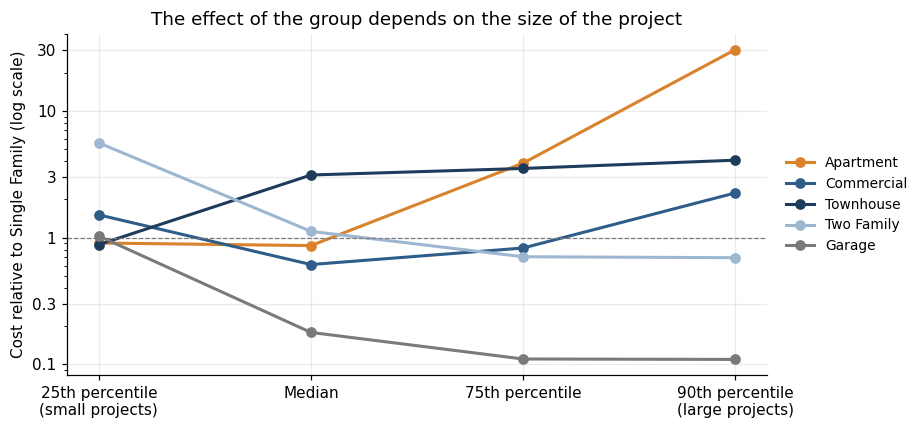

In [33]:
# Select five groups with contrasting patterns and draw their ratio to Single Family at each quantile
groups = {"Apartment": ORANGE, "Commercial": BLUE, "Townhouse": NAVY, "Two Family": LIGHT_BLUE, "Garage": GREY}
quantiles = ["q25", "q50", "q75", "q90"]

fig, ax = plt.subplots(figsize=(8.5, 4))
for name, color in groups.items():
    ax.plot(range(4), quantile_table.loc[name, quantiles], marker="o", color=color, lw=2, label=name)
ax.axhline(1, color=GREY, lw=0.8, ls="--")

# Use a log scale with plain labels and name the quantiles in words
ax.set_yscale("log")
ax.set_yticks([0.1, 0.3, 1, 3, 10, 30])
ax.set_yticklabels(["0.1", "0.3", "1", "3", "10", "30"])
ax.yaxis.set_minor_formatter(mtick.NullFormatter())
ax.set_xticks(range(4))
ax.set_xticklabels(["25th percentile\n(small projects)", "Median", "75th percentile", "90th percentile\n(large projects)"])
ax.set(ylabel="Cost relative to Single Family (log scale)",
       title="The effect of the group depends on the size of the project")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9)
plt.tight_layout()
plt.show()

Each line follows one group across the cost levels, and the dashed line at 1 marks the same cost as single family. A flat line would mean a constant difference, and none of them is flat. Apartments are about as expensive as single family at the median and 30 times more expensive among the largest projects. Two Family projects start more than five times higher at the 25th percentile, because single family includes many small improvements that lower its 25th percentile, and end below single family at the 90th percentile (0.69). Garages are cheaper at every level except the smallest, and the gap widens at the top (0.11).

The largest non-residential projects are therefore much larger than the largest houses.

The quantile ratios may also be affected by the repeated amounts of section 2.3. The same models are fitted without the amounts that appear at least 100 times, and the five groups of the chart are compared.

In [34]:
# Same models without the amounts that appear at least 100 times
model_clean = model_data[model_data["estprojectcost_clean"].map(cost_all.value_counts()) < 100]
ols_clean = smf.ols(formula, data=model_clean).fit()
is_group_clean = ols_clean.params.index.str.startswith("C(permitclassgroup")
ratios_clean = np.exp(ols_clean.params[is_group_clean])
ratios_clean.index = ratios_clean.index.str.extract(r"\[T\.(.*)\]", expand=False)
print(f"Projects: {int(ols_clean.nobs):,} | R-squared: {ols_clean.rsquared:.2f}")

# Quantile regression with the same formula at the same four quantiles
results_clean = {"mean (OLS)": ratios_clean}
for q in [0.25, 0.5, 0.75, 0.9]:
    fit = smf.quantreg(formula, data=model_clean).fit(q=q, max_iter=2000)
    g = fit.params[fit.params.index.str.startswith("C(permitclassgroup")]
    g.index = g.index.str.extract(r"\[T\.(.*)\]", expand=False)
    results_clean[f"q{int(q * 100)}"] = np.exp(g)
quantile_table_clean = pd.DataFrame(results_clean)

# Compare the five groups of the chart, as reported and without the repeated amounts
five = list(groups)
comparison = pd.concat({"As reported": quantile_table.loc[five],
                        "Without repeated amounts": quantile_table_clean.loc[five]}, axis=1)
comparison.round(2)

Projects: 331,344 | R-squared: 0.17


As reported                          Without repeated amounts  \
            mean (OLS)   q25   q50   q75    q90               mean (OLS)   
Apartment         2.49  0.91  0.86  3.86  30.35                     7.05   
Commercial        1.29  1.51  0.61  0.83   2.25                     2.45   
Townhouse         2.33  0.88  3.11  3.51   4.07                     2.07   
Two Family        1.92  5.58  1.12  0.71   0.69                     1.52   
Garage            0.38  1.03  0.18  0.11   0.11                     0.27   

                                      
             q25   q50    q75    q90  
Apartment   2.54  3.67  25.63  48.05  
Commercial  2.58  1.00   2.52   7.90  
Townhouse   0.74  2.85   3.49   4.07  
Two Family  5.02  0.77   0.67   0.68  
Garage      0.80  0.11   0.09   0.10

The pattern holds without the repeated amounts: no group has a flat line, garages stay far below single family (0.10 at the 90th percentile), Two Family projects start about five times higher at the 25th percentile (5.02) and end below single family (0.68), townhouses stay between 2.85 and 4.07 times single family from the median up, and apartments remain the group with the largest ratio at the 90th percentile (48.05). Some ratios do change. Apartments go from 0.86 to 3.67 at the median, and commercial projects go from 0.61 to 1.00 at the median and from 2.25 to 7.90 at the 90th percentile.

The statement that matters is therefore the pattern, that the effect of the group depends on the size of the project, and not the value of each ratio. The fit improves, from an R-squared of 0.11 to 0.17, but most of the variation remains inside the groups.

**Summary of Chapter 2: The money**

**Question:** How large are the projects, and what separates the small from the very large?

**Answer:** The typical project has an estimated cost of 55,549 dollars, but the costs form two groups, one around 20,000 dollars and one between about 150,000 and 370,000, and a few very large projects pull the average up to 273,874. What separates small from large is the kind of work: garages have a median of 19,921 dollars, single family 100,000 and townhouses 410,202. The value is concentrated in a few projects, and that holds under every check. The typical cost, however, depends on amounts that repeat, so the level of the median and its trend over the years are not reliable.

**What the evidence shows:**

* A single cost figure describes almost no project: the average is almost five times the median, and the median falls in the dip between the two groups, which remain when the repeated amounts are removed.
* The value is concentrated: the largest 1% of the projects hold 47.6% of the total estimated value (48.6% without the repeated amounts), the largest 10% hold 69.8% (69.7%), and the cheaper half holds 3.5%.
* The effect of a group depends on the size of the project: apartments cost 30 times a single family project at the 90th percentile and garages 0.11 times. The pattern holds without the repeated amounts (48.05 and 0.10), although some individual ratios change.
* The repeated amounts are common: 132,457 applications (28.6% of those with a cost) share an amount that appears at least 100 times, and without them the median doubles, from 55,549 to 109,999 dollars.
* The trend of the median is not reliable. For all costs it falls 70% between 2006 and 2007, and 51% between 2000 and 2025 in 2025 dollars. Without the repeated amounts the fall of 2007 is 23%, the large fall comes in 2008 (when the mix of single family work changes), and the median in 2025 dollars is 5% higher in 2025 than in 2000 (175,912 against 184,129).

# Chapter 3. The rhythm

**Question:** How has the volume of applications moved over the years and the seasons?

**Why it matters:** Volume decides how much capacity the process needs. Staffing has to follow the busy periods, not the average.

## 3.1 What is measured

Volume is the number of applications by application date. Before counting, it is necessary to know which periods are complete, because a partial year or month has fewer applications and looks like a fall.

In [35]:
# Show the period covered by the data
print(f"First application: {df['applieddate'].min():%Y-%m-%d}, last: {df['applieddate'].max():%Y-%m-%d}")

# Count the applications by year and list the years that are not complete
span = df.groupby("application_year").agg(
    applications=("permitnum", "size"),
    first=("applieddate", "min"),
    last=("applieddate", "max"),
    complete=("full_year", "first"),
)
partial_years = span[~span["complete"]]
partial_years.style.format({"applications": "{:,.0f}", "first": "{:%Y-%m-%d}", "last": "{:%Y-%m-%d}"})

First application: 1999-06-22, last: 2026-11-05


,applications,first,last,complete
application_year,,,,
1999,"6,991",1999-06-22,1999-12-30,False
2026,"21,009",2026-01-01,2026-11-05,False


The data covers applications from 22 June 1999 to 5 November 2026. The two ends are partial years: 1999 has 6,991 applications from June onward, and 2026 has 21,009 up to November. Together they hold 5.6% of all applications.

Comparisons by year use the 26 complete years, from 2000 to 2025 (475,411 applications). A partial year would look like a fall or a rise by itself, so it is shown apart or left out.

## 3.2 Volume over the years

The number of applications is counted for each year. Complete years are drawn in blue and the two partial years in light blue, so that they are not read as a fall or a rise. The labels mark the peak of each of the three waves, in 2006, 2014 and 2024.

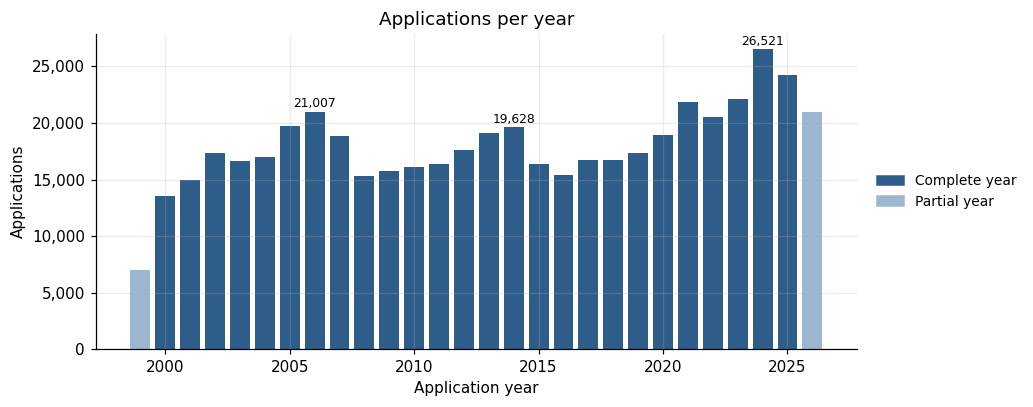

In [36]:
# Draw the number of applications per year, with partial years in a lighter color
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.bar(span.index, span["applications"], color=[BLUE if c else LIGHT_BLUE for c in span["complete"]])
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

# Label the peaks of 2006, 2014 and 2024
for year in [2006, 2014, 2024]:
    ax.text(year, span.loc[year, "applications"] + 400, f"{span.loc[year, 'applications']:,}",
            ha="center", fontsize=8)

ax.set(xlabel="Application year", ylabel="Applications", title="Applications per year")
ax.legend(handles=[Patch(color=BLUE, label="Complete year"), Patch(color=LIGHT_BLUE, label="Partial year")],
          frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9)
plt.tight_layout()
plt.show()

The volume of applications almost doubles over the period, from 13,551 in 2000 to 26,521 in 2024, but it does not grow in a straight line. There are two waves with a clear peak and fall. Applications rise to 21,007 in 2006 and fall 27% to 15,268 in 2008. They rise again to 19,628 in 2014 and fall 22% to 15,358 in 2016. Since then the volume has risen from 15,358 in 2016 to 26,521 in 2024, the strongest rise in the series.

2025 is 9% lower than 2024, at 24,207, and still well above any year before 2021. The partial year 2026 already has 21,009 applications up to 5 November.

## 3.3 What the volume is made of

The total hides which kind of work moves it. Applications are counted by permit type for each complete year. Only the four main types are drawn: Environmental Restoration has 747 applications in the whole period, about 0.15% of the total.

In [37]:
# Count the applications by year and permit type, using complete years and the four main types
complete_years = df[df["full_year"]]
by_type = complete_years.groupby(["application_year", "permittype"]).size().unstack(fill_value=0)
by_type = by_type.drop(columns="Environmental Restoration Permit")

# Convert the counts to shares of each year and show four selected years
shares_by_type = by_type.div(by_type.sum(axis=1), axis=0)
shares_by_type.loc[[2000, 2010, 2020, 2025]].style.format("{:.1%}")

permittype,Commercial / Multi Family Project,Demolition,Residential Improvement Project,Single Construction Permit
application_year,,,,
2000,22.7%,2.4%,30.4%,44.4%
2010,20.1%,4.1%,45.0%,30.8%
2020,17.3%,2.5%,62.0%,18.3%
2025,21.2%,3.9%,50.5%,24.5%


Residential improvements grow from 30.4% of the applications in 2000 to 62.0% in 2020 and 50.5% in 2025, and they are now the largest type. Single construction permits go the other way, from 44.4% to 18.3% in 2020 and 24.5% in 2025. In the 26 complete years, commercial and multi-family projects range between 15.6% and 25.7% of the applications, and demolitions between 2.1% and 5.3%.

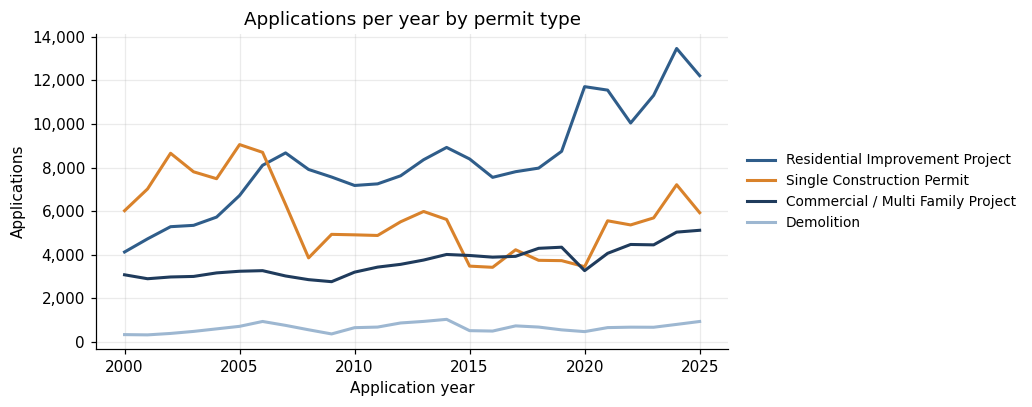

In [38]:
# Draw the number of applications per year for each of the four main permit types
order = ["Residential Improvement Project", "Single Construction Permit",
         "Commercial / Multi Family Project", "Demolition"]
colors = [BLUE, ORANGE, NAVY, LIGHT_BLUE]

fig, ax = plt.subplots(figsize=(9.5, 3.8))
for permit_type, color in zip(order, colors):
    ax.plot(by_type.index, by_type[permit_type], color=color, lw=2, label=permit_type)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set(xlabel="Application year", ylabel="Applications", title="Applications per year by permit type")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9)
plt.tight_layout()
plt.show()

The waves of the previous section come largely from single construction permits, the orange line. They peak at 9,057 in 2005 and fall to 3,854 in 2008, a drop of 57%. Among the four main types, this type explains 4,847 of the 5,833 fewer applications between 2006 and 2008, and about half of the fall between 2014 and 2016 (2,197 of 4,233).

The other lines are steadier. Commercial and multi-family projects stay between 2,761 and 5,121 applications a year, and residential improvements rise from 4,124 in 2000 to 12,223 in 2025, with some dips on the way. The recent rise has two sources: residential improvements, from 7,552 in 2016 to 13,470 in 2024, and single construction permits, from 3,421 to 7,213.

## 3.4 The seasons

Applications are grouped by calendar month, using the complete years from 2000 to 2025. Each bar is the share of a year's applications that falls in that month. The busiest month is in orange and the quietest in light blue.

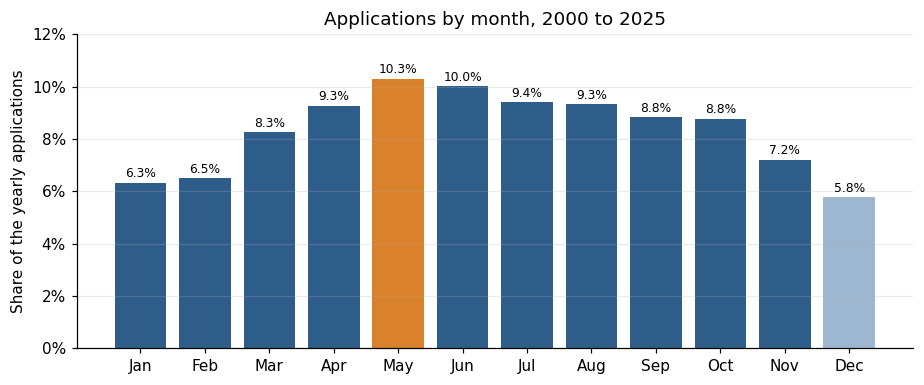

In [39]:
# Compute the share of the yearly applications that falls in each month
import calendar
monthly = complete_years.groupby("application_month").size()
monthly_share = monthly / monthly.sum()

# Draw the shares, highlighting the busiest and the quietest month
colors = [ORANGE if m == monthly_share.idxmax() else LIGHT_BLUE if m == monthly_share.idxmin() else BLUE
          for m in monthly_share.index]
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.bar(monthly_share.index, monthly_share.values, color=colors)
for month, value in monthly_share.items():
    ax.text(month, value + 0.002, f"{value:.1%}", ha="center", fontsize=8)
ax.set_xticks(range(1, 13))
ax.set_xticklabels([calendar.month_abbr[m] for m in range(1, 13)])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set(ylim=(0, 0.12), ylabel="Share of the yearly applications", title="Applications by month, 2000 to 2025")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

May is the busiest month, with 10.3% of the yearly applications, and December is the quietest, with 5.8%. The busiest month has 1.8 times the applications of the quietest. April to October hold 65.9% of the year's applications.

The pattern is stable. May or June is the busiest month in 18 of the 26 years, and December or January is the quietest in 23.

Not every kind of work follows the same seasons. The next table compares the busiest and the quietest month for each of the four main permit types.

In [40]:
# Compute the monthly shares of each of the four main permit types
main_types = ["Residential Improvement Project", "Single Construction Permit",
              "Commercial / Multi Family Project", "Demolition"]
by_type_month = (complete_years[complete_years["permittype"].isin(main_types)]
                 .groupby(["permittype", "application_month"]).size().unstack())
type_share = by_type_month.div(by_type_month.sum(axis=1), axis=0)

# Show the busiest and the quietest month of each type and the ratio between them
seasonality = pd.DataFrame({
    "busiest month": type_share.idxmax(axis=1).map(lambda m: calendar.month_abbr[m]),
    "quietest month": type_share.idxmin(axis=1).map(lambda m: calendar.month_abbr[m]),
    "busiest to quietest": type_share.max(axis=1) / type_share.min(axis=1),
}).sort_values("busiest to quietest", ascending=False)
seasonality.style.format({"busiest to quietest": "{:.2f}"})

,busiest month,quietest month,busiest to quietest
permittype,,,
Residential Improvement Project,May,Dec,2.35
Demolition,May,Dec,2.04
Commercial / Multi Family Project,Jun,Jan,1.56
Single Construction Permit,Apr,Dec,1.48


Seasonality is strongest in residential improvements and demolitions, where the busiest month (May) has 2.35 and 2.04 times the applications of the quietest (December). It is weaker in commercial and multi-family projects (1.56, June against January) and in single construction permits (1.48, April against December). The data does not say why, but the work that depends most on the weather may be the work that is most concentrated in the warm months.

## 3.5 2026 so far

The partial year 2026 cannot be compared with the full years, so each year is cut at the same point: from 1 January to 5 November, the last date in the data. The comparison then answers whether this year is running above or below the recent pace.

In [41]:
# Keep the applications from 1 January up to the same day and month as the last date in the data
cutoff = df["applieddate"].max()
in_window = ((df["applieddate"].dt.month < cutoff.month) |
             ((df["applieddate"].dt.month == cutoff.month) & (df["applieddate"].dt.day <= cutoff.day)))
year_to_date = df[in_window].groupby("application_year").size().loc[2000:2026]

# Compare 2026 with each of the previous six years over the same days
label = f"1 Jan to {cutoff.day} {calendar.month_abbr[cutoff.month]}"
print(f"2026: {year_to_date.loc[2026]:,} applications, {label}")
recent = year_to_date.loc[2020:2025].to_frame(f"applications, {label}")
recent["2026 compared with this year"] = year_to_date.loc[2026] / recent.iloc[:, 0] - 1
recent.style.format({recent.columns[0]: "{:,.0f}", "2026 compared with this year": "{:+.1%}"})

2026: 21,009 applications, 1 Jan to 5 Nov


,"applications, 1 Jan to 5 Nov",2026 compared with this year
application_year,,
2020,"16,284",+29.0%
2021,"19,203",+9.4%
2022,"18,503",+13.5%
2023,"19,137",+9.8%
2024,"23,495",-10.6%
2025,"21,515",-2.4%


Up to 5 November, 2026 has 21,009 applications. That is 2.4% below 2025 (21,515) and 10.6% below 2024 (23,495), the busiest year so far, and between 9% and 29% above 2020 to 2023.

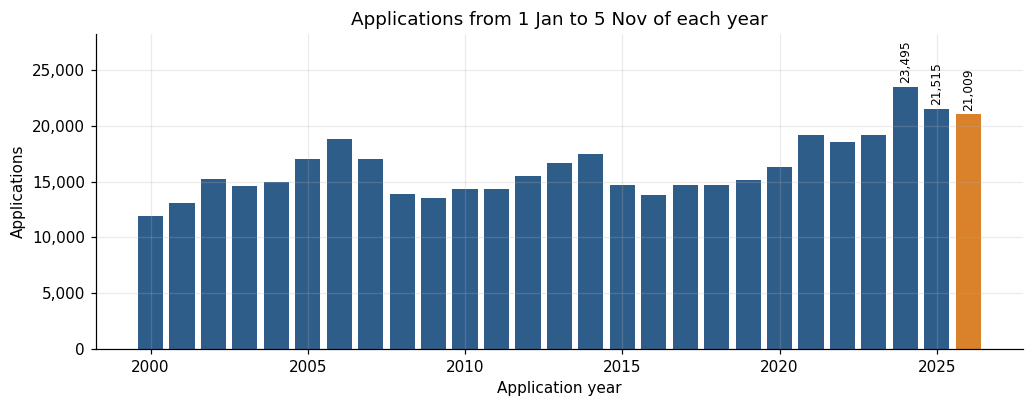

In [42]:
# Draw the applications of each year from 1 January to the cutoff date, with 2026 in orange
fig, ax = plt.subplots(figsize=(9.5, 3.8))
bar_colors = [ORANGE if year == 2026 else BLUE for year in year_to_date.index]
ax.bar(year_to_date.index, year_to_date.values, color=bar_colors)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

# Label the last three years, with the text turned 90 degrees so the labels do not overlap
for year in [2024, 2025, 2026]:
    ax.text(year, year_to_date.loc[year] + 300, f"{year_to_date.loc[year]:,}",
            ha="center", va="bottom", rotation=90, fontsize=8)

ax.set_ylim(0, year_to_date.max() * 1.2)
ax.set(xlabel="Application year", ylabel="Applications",
       title=f"Applications from {label} of each year")
plt.tight_layout()
plt.show()

At this point of the year, 2026 is the third highest of the 27 years, behind 2024 and 2025, and above any year before 2021. The volume is not falling back to the levels of the last decade, it is staying at the high level reached since 2021.

**Summary of Chapter 3: The rhythm**

**Question:** How has the volume of applications moved over the years and the seasons?

**Answer:** The volume almost doubled between 2000 and 2024, from 13,551 to 26,521 applications, but it moved in waves: it peaked at 21,007 in 2006 and fell to 15,268 in 2008, and it peaked again at 19,628 in 2014 and fell to 15,358 in 2016. Within each year, May is the busiest month (10.3% of the applications) and December the quietest (5.8%). In 2026, up to 5 November, there are 21,009 applications, 2.4% below 2025 and 10.6% below 2024.

**What the evidence shows:**

* The waves come largely from single construction permits, which fell from 9,057 in 2005 to 3,854 in 2008. The recent rise has two sources: residential improvements (7,552 in 2016 to 13,470 in 2024) and single construction permits (3,421 to 7,213).
* The mix of work has changed: residential improvements are now half of the applications (50.5% in 2025, against 30.4% in 2000), and single construction permits have fallen from 44.4% to 24.5%.
* The seasons are stable and strongest in residential improvements and demolitions, where the busiest month has about twice the applications of the quietest (2.35 and 2.04 times). April to October hold 65.9% of the year's applications.
* 2026 is not falling back to the levels of the last decade: it is the third highest of 27 years at this point of the year, and 9% to 29% above 2020 to 2023.

# Chapter 4. The map

**Question:** Where is the activity concentrated?

**Why it matters:** Location shows where growth and pressure are, and where the permit office's attention is needed.

## 4.1 What is measured

Each application records a community and, in most cases, coordinates. Before any map or ranking, the first step is to see how many applications have a usable location, and whether that share is the same in the three periods used in Chapter 1. A map only represents the applications that can be placed on it.

In [43]:
# Count the applications with usable coordinates and with a community
has_coords = df["latitude_clean"].notna() & df["longitude_clean"].notna()
has_community = df["communityname_clean"].notna()
print(f"Applications: {len(df):,}")
print(f"With coordinates: {has_coords.sum():,} ({has_coords.mean():.1%})")
print(f"With a community: {has_community.sum():,} ({has_community.mean():.1%})")
print(f"Different communities: {df['communityname_clean'].nunique():,}")

# Check whether the share with a location changes between periods
period = pd.cut(df["application_year"], bins=[1998, 2016, 2020, 2026],
                labels=["Before 2017", "2017 to 2020", "2021 to 2026"])
coverage_by_period = pd.DataFrame({
    "with coordinates": has_coords.groupby(period, observed=True).mean(),
    "with community": has_community.groupby(period, observed=True).mean(),
})
coverage_by_period.style.format("{:.1%}")

Applications: 503,411
With coordinates: 502,492 (99.8%)
With a community: 502,492 (99.8%)
Different communities: 316


,with coordinates,with community
application_year,,
Before 2017,99.7%,99.7%
2017 to 2020,99.9%,99.9%
2021 to 2026,100.0%,100.0%


Almost every application can be placed: 502,492 of the 503,411 (99.8%) have coordinates and a community, and only 919 do not. The data covers 316 different communities. The share with a location is also stable over time, between 99.7% and 100.0% in the three periods, so the maps and rankings that follow are not biased by missing locations in any period.

## 4.2 Where the activity concentrates

The applications are counted by community and ranked. Two numbers summarize how concentrated the activity is: the share held by the 10 and 20 busiest communities, and how many communities are needed to reach half of all applications.

In [44]:
# Count the applications in each community and compute each community's share of the total
by_community = df["communityname_clean"].value_counts()
share = by_community / by_community.sum()

# Measure the concentration: top 10, top 20 and the number of communities that hold half of the applications
communities_for_half = int((share.cumsum() < 0.5).sum() + 1)
print(f"Communities with applications: {len(by_community)}")
print(f"The 10 busiest hold {share.head(10).sum():.1%} of the applications")
print(f"The 20 busiest hold {share.head(20).sum():.1%} of the applications")
print(f"Half of the applications are in the {communities_for_half} busiest communities")

Communities with applications: 316
The 10 busiest hold 20.7% of the applications
The 20 busiest hold 33.4% of the applications
Half of the applications are in the 40 busiest communities


The activity is spread over many communities. The 10 busiest hold 20.7% of the applications, the 20 busiest hold 33.4%, and it takes the 40 busiest of the 316 communities (13%) to reach half of all applications. No small group of communities dominates: the 10 busiest hold about a fifth of the applications.

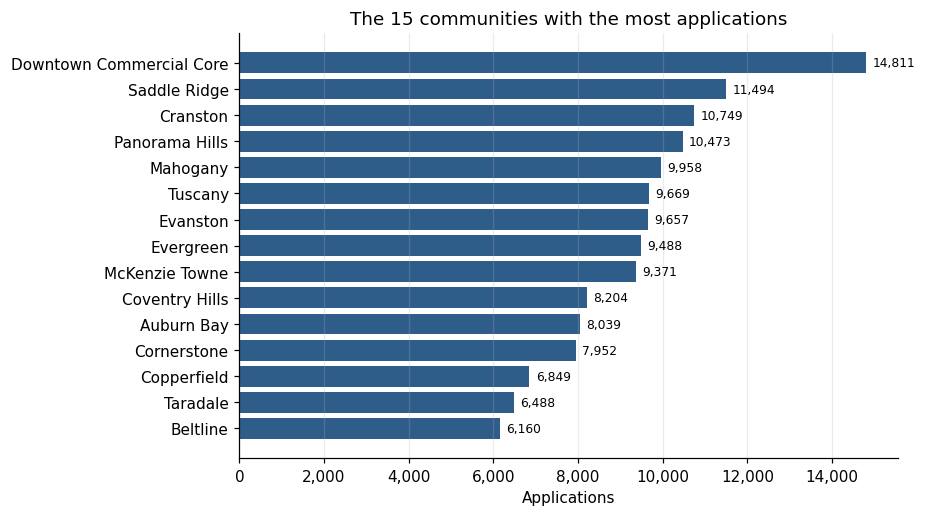

In [45]:
# Draw the 15 communities with the most applications
top_communities = by_community.head(15)
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.barh(top_communities.index.str.title().str.replace("Mckenzie", "McKenzie"), top_communities.values, color=BLUE)
ax.invert_yaxis()
for i, value in enumerate(top_communities.values):
    ax.text(value + 150, i, f"{value:,}", va="center", fontsize=8)
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set(xlabel="Applications", ylabel="", title="The 15 communities with the most applications")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Downtown Commercial Core has the most applications, 14,811, about 3% of the total, followed by Saddle Ridge (11,494), Cranston (10,749) and Panorama Hills (10,473). The 15 communities in the chart range from 14,811 down to 6,160 applications (Beltline). After Downtown Commercial Core, the decline is gradual with no sharp break, which agrees with the spread seen in the numbers above. The next step places these communities on the map.

## 4.3 The map

Each application with coordinates is a point. Before drawing them, the range of the coordinates is checked, so that wrong points do not stretch the map.

In [46]:
# Check the range of the coordinates, including the extreme percentiles
located = df.loc[has_coords, ["latitude_clean", "longitude_clean"]]
located.describe(percentiles=[0.001, 0.999]).round(4)

,latitude_clean,longitude_clean
count,502492.0000,502492.0000
mean,51.0387,-114.0659
std,0.0979,0.0902
min,50.8486,-114.3042
0.1%,50.8530,-114.2792
50%,51.0494,-114.0717
99.9%,51.1943,-113.8889
max,51.2124,-113.8607


All the coordinates fall inside a small area: latitudes from 50.85 to 51.21 and longitudes from -114.30 to -113.86. The extreme values are close to the 0.1% and 99.9% percentiles, so there are no wrong points far from the city, and the map needs no filter. The 919 applications with coordinates of zero were already set to missing in notebook 1, so they are not in this count.

The coordinates are now drawn on a map. The left map shows the streets alone, with detail, so that each area can be located. The right map shows the same area with the applications grouped in hexagonal cells, colored by the number of applications each one holds on a log scale, over a light grey base map that lets the colors stand out. Both base maps come from Esri. The coordinates are converted to the projection used by web maps (Web Mercator), because the tiles are drawn in that system.

In [47]:
# Install the library that adds map tiles to a matplotlib chart
!pip install -q contextily

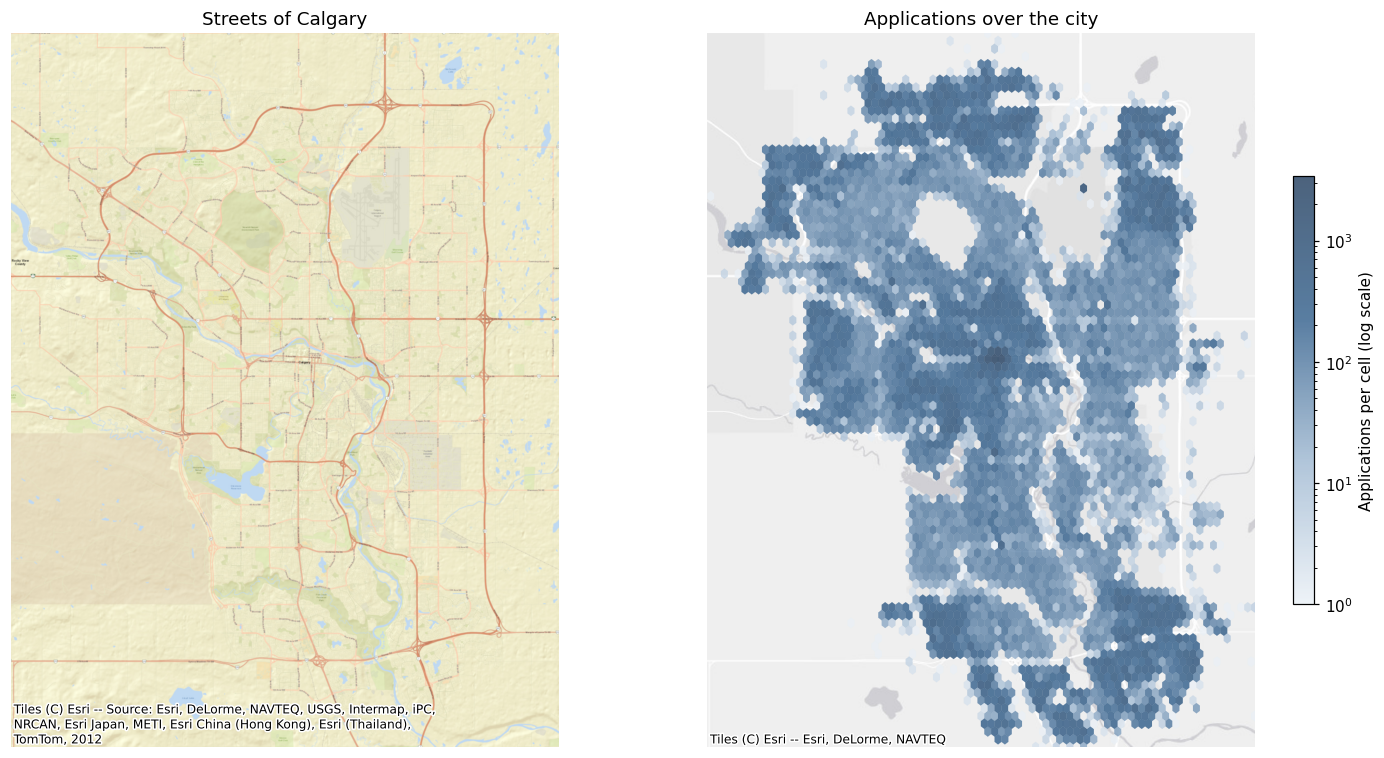

In [48]:
# Tools for the color scale and the base map (defined here so the cell runs on its own)
import contextily as ctx
from matplotlib.colors import LinearSegmentedColormap, LogNorm

# Colors of the density scale and the applications that have coordinates
cmap = LinearSegmentedColormap.from_list("blues", ["#EAF0F6", LIGHT_BLUE, BLUE, NAVY])
located = df[["latitude_clean", "longitude_clean"]].dropna()

# Convert longitude and latitude to Web Mercator meters, the system of the map tiles
earth_radius = 6378137
map_x = np.radians(located["longitude_clean"]) * earth_radius
map_y = np.log(np.tan(np.pi / 4 + np.radians(located["latitude_clean"]) / 2)) * earth_radius

# Two panels with the same extent: detailed streets on the left, density over a grey base map on the right
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax in axes:
    ax.set_xlim(map_x.min(), map_x.max())
    ax.set_ylim(map_y.min(), map_y.max())
    ax.set_aspect("equal")

# Density hexagons on the right panel
hexes = axes[1].hexbin(map_x, map_y, gridsize=80, mincnt=1, cmap=cmap, norm=LogNorm(),
                       alpha=0.8, linewidths=0.1, zorder=2)

# Base maps: Esri street map with all the streets (higher zoom) on the left, grey canvas on the right
ctx.add_basemap(axes[0], source=ctx.providers.Esri.WorldStreetMap, crs="EPSG:3857", zoom=13, zorder=1)
ctx.add_basemap(axes[1], source=ctx.providers.Esri.WorldGrayCanvas, crs="EPSG:3857", zorder=1)
for ax in axes:
    ax.set_axis_off()

# Titles and color scale
axes[0].set_title("Streets of Calgary")
axes[1].set_title("Applications over the city")
colorbar = fig.colorbar(hexes, ax=axes[1], shrink=0.6)
colorbar.set_label("Applications per cell (log scale)")
plt.tight_layout()
plt.show()

Placed over the streets, the density follows the shape of the city. The applications fill the area inside the ring road and stop close to it, with only a few scattered cells outside. The empty areas also have an explanation on the street map: the large empty space in the northwest matches a large green area, the gap between the north and northeast clusters matches the airport grounds, and the thin empty bands in the center follow the river valleys. The darkest cell sits in the center, and the dark blocks at the north, northeast, south and southeast edges are the areas with the most applications outside the center.

## 4.4 What differs by area

The ranking says where the activity is, but not what kind of work it is. This step compares the 10 busiest communities with the whole city on four measures: the share of new construction, the share of non-residential projects, the most common type of permit, and the typical project cost. The comparison shows whether the busiest areas are alike or have a different profile.

In [49]:
# Profile of one group of applications: size, mix of work and typical cost
def profile(g):
    types = g["permitclassgroup"].value_counts()
    return {
        "Applications": len(g),
        "New construction (%)": (g["workclassmapped_clean"] == "New").mean() * 100,
        "Non-residential (%)": (g["permitclassmapped"] == "Non-Residential").mean() * 100,
        "Most common type": types.index[0],
        "Its share (%)": types.iloc[0] / len(g) * 100,
        "Median cost ($)": g["estprojectcost_clean"].median(),
    }

# Profile of each of the 10 busiest communities
names = df["communityname_clean"]
busiest = names.value_counts().head(10).index
rows = {name: profile(df[names == name]) for name in busiest}

# Add the whole city as the reference row
rows["All Calgary"] = profile(df)

# Names in title case (with the McKenzie fix) and the comparison table
area_profile = pd.DataFrame(rows).T
area_profile.index = area_profile.index.str.title().str.replace("Mckenzie", "McKenzie")
area_profile.style.format({
    "Applications": "{:,.0f}",
    "New construction (%)": "{:.1f}",
    "Non-residential (%)": "{:.1f}",
    "Its share (%)": "{:.1f}",
    "Median cost ($)": "{:,.0f}",
})

,Applications,New construction (%),Non-residential (%),Most common type,Its share (%),Median cost ($)
Downtown Commercial Core,"14,811",4.1,98.0,Commercial,85.2,"80,000"
Saddle Ridge,"11,494",66.1,3.0,Single Family,66.3,"91,405"
Cranston,"10,749",70.8,1.0,Single Family,81.1,"130,461"
Panorama Hills,"10,473",61.0,1.3,Single Family,80.3,"127,333"
Mahogany,"9,958",75.2,2.2,Single Family,66.6,"205,257"
Tuscany,"9,669",55.4,1.2,Single Family,86.9,"44,741"
Evanston,"9,657",66.8,2.7,Single Family,73.3,"137,966"
Evergreen,"9,488",63.2,0.9,Single Family,82.7,"89,668"
McKenzie Towne,"9,371",69.3,4.7,Single Family,55.6,"38,240"
Coventry Hills,"8,204",62.3,1.9,Single Family,72.9,"42,434"


The busiest communities do not share one profile. Downtown Commercial Core is a different kind of area: 98.0% of its applications are non-residential, 85.2% are commercial, and only 4.1% are new construction. The other nine communities are residential, with between 0.9% and 4.7% of non-residential projects against 16.9% in the whole city, and single family projects are the most common type in all of them (from 55.6% to 86.9% of their applications). All nine also have more new construction than the city: from 55.4% to 75.2%, against 48.9%.

The typical cost varies more than the mix of work. The median goes from 38,240 dollars in McKenzie Towne to 205,257 in Mahogany, which is 3.7 times the city median of 55,549. Three communities (McKenzie Towne, Coventry Hills and Tuscany) are below the city median, and the other seven are above it. The share of new construction does not explain the difference: McKenzie Towne has 69.3% of new construction and the lowest median, while Mahogany has 75.2% and the highest.

## 4.5 Where the activity moved

The ranking of Chapter 4 adds all the years together, so it hides any movement. To see whether the activity moved, each community is measured by its share of all the applications of a period, because the periods have different lengths and 2026 is incomplete. The change is the difference between the share in 2021 to 2026 and the share before 2017, in percentage points. The chart shows the six communities that gained the most and the six that lost the most.

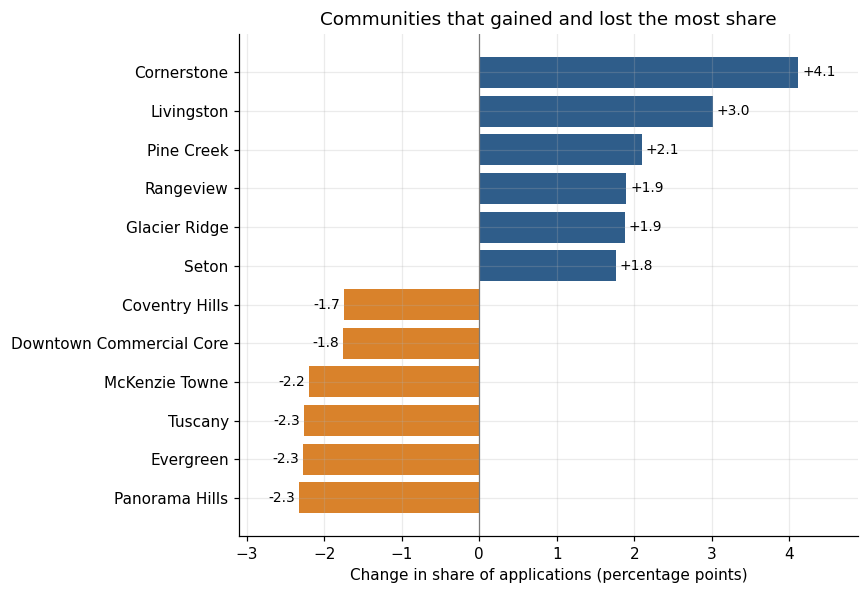

application_year,Before 2017,2017 to 2020,2021 to 2026
communityname_clean,,,
Cornerstone,0.08,2.88,4.19
Livingston,0.02,2.57,3.02
Pine Creek,0.00,0.25,2.10
Rangeview,0.00,0.00,1.90
Glacier Ridge,0.00,0.00,1.87
Seton,0.03,1.31,1.80
Coventry Hills,2.34,0.64,0.60
Downtown Commercial Core,3.51,2.88,1.75
McKenzie Towne,2.73,0.74,0.54


In [50]:
# Group the applications in the three periods used in the notebook
periods = pd.cut(df["application_year"], bins=[0, 2016, 2020, 3000],
                 labels=["Before 2017", "2017 to 2020", "2021 to 2026"])

# Share of each community in the applications of its period (communities with a name only)
community = df["communityname_clean"].str.title().str.replace("Mckenzie", "McKenzie")
counts = pd.crosstab(community, periods)
share_by_period = counts / counts.sum() * 100

# Change in share between the first and the last period, and the 6 biggest gains and losses
change = (share_by_period["2021 to 2026"] - share_by_period["Before 2017"]).sort_values()
moves = pd.concat([change.head(6), change.tail(6)])

# Horizontal bars: blue for gains, orange for losses, with the value at the end of each bar
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(moves.index, moves.values, color=[BLUE if v > 0 else ORANGE for v in moves.values])
ax.axvline(0, color=GREY, linewidth=0.8)
for y, v in enumerate(moves.values):
    ax.text(v + (0.05 if v > 0 else -0.05), y, f"{v:+.1f}", va="center",
            ha="left" if v > 0 else "right", fontsize=9)
ax.set_xlabel("Change in share of applications (percentage points)")
ax.set_title("Communities that gained and lost the most share")
ax.margins(x=0.12)
plt.tight_layout()
plt.show()

# Share in each period for the same communities
share_by_period.loc[moves.index[::-1]].round(2)

The activity moved toward communities that barely appeared in the data before 2017. Cornerstone goes from 0.08% of the applications to 4.19%, Livingston from 0.02% to 3.02%, and Pine Creek, Rangeview and Glacier Ridge go from almost nothing (0.00% before 2017) to between 1.87% and 2.10%. Seton rises from 0.03% to 1.80%. Together, these six communities hold 14.9% of the applications of 2021 to 2026.

The communities that lose share are established ones that were among the busiest before 2017, with between 2.3% and 3.0% each (Downtown Commercial Core had 3.51%). Five of the six fall to between 0.5% and 0.9% already in 2017 to 2020 and stay there in 2021 to 2026. Downtown Commercial Core declines more slowly, from 3.51% to 2.88% and then to 1.75%.

These are changes in share, not in the number of applications. A community can lose share while still receiving applications, because the new communities add to the total.

**Summary of Chapter 4: The map**

**Question:** Where do the applications come from, and has that changed over time?

**Answer:** The applications are spread over the whole city: the 10 busiest communities hold about a fifth of them, and each of them has its own profile. Over time the activity moved from established communities to new ones that barely appear in the data before 2017.

**What the evidence shows:**

* 502,492 applications (99.8%) have coordinates and a community, spread over 316 communities.
* The 10 busiest communities hold 20.7% of the applications, the 20 busiest hold 33.4%, and 40 communities hold half of them. Downtown Commercial Core leads with 14,811 applications.
* The map shows the activity in every part of the city, with the darkest cells in the center and dense blocks at the north, northeast, south and southeast edges. The few empty areas inside the city match a large park, the airport grounds and the river valleys on the street map.
* The busiest communities have different profiles. Downtown Commercial Core is 98.0% non-residential, while the other nine are residential, with single family projects as the most common type. The median cost goes from 38,240 dollars in McKenzie Towne to 205,257 in Mahogany, against 55,549 in the whole city.
* The share of six communities (Cornerstone, Livingston, Pine Creek, Rangeview, Glacier Ridge and Seton) goes from almost nothing before 2017 to 14.9% of the applications in 2021 to 2026. Established communities such as Panorama Hills, Tuscany and Evergreen go from between 2.8% and 3.0% to between 0.5% and 0.7%.

# Conclusions

The four chapters and the data checks lead to five recommendations for a permit office, and to a set of limits that a reader should keep in mind.

### Recommendations

1. **Publish the wait as a range by type of permit.** A typical application is issued in 14 days and one in ten waits more than 49 days. Since 2021 the median is 19 days and the 90th percentile 72, and commercial and multi-family projects take a median of 39 days.
2. **Track the slow tail and the applications that never finish.** The 90th percentile went from 42 to 72 days between the first and the last period, while the median went from 14 to 19. A success rate that ignores the applications that end without a permit overstates it by 1.8 points (98.4% against 96.6%).
3. **Plan capacity by season and by wave.** May holds 10.3% of the yearly applications and December 5.8%, and the volume moved in waves, with peaks in 2006 and 2014. Up to 5 November, 2026 is 2.4% below 2025 and the third highest of 27 years at this point of the year.
4. **Follow the growth by community.** The 10 busiest communities hold 20.7% of the applications, and six communities that barely appeared before 2017 hold 14.9% of those of 2021 to 2026.
5. **Report costs as ranges and concentration, not as one typical value, and review the standard amounts at intake.** The largest 1% of the projects hold 47.6% of the estimated value, while 28.6% of the declared costs share an amount that appears at least 100 times, which makes the median and its trend unreliable.

### Limitations

* The costs are declared estimates, not final costs. Many share the same amount, so the level of the median and its trend over the years should not be read as the real cost of projects.
* The wait counts calendar days between the application and the issue date. The data do not say whether a delay comes from the office or from the applicant.
* The reasons for the changes are not in the data. The wait fell in 2017 to 2020 and rose from 2021, and the activity moved between communities, but the dataset does not explain why.
* The data are a snapshot of 2026-11-05. 2026 is incomplete, so the yearly series use complete years only, and 5,212 applications are still waiting.
* Some fields are limited. Square footage is missing in 69.0% of the applications and is not used, and the location is missing in 0.2%.
* The adjustment for inflation is an approximation. It uses the consumer price index of Calgary, which measures consumer prices in general and not construction costs.

### Reproducibility

* **Environment:** the notebook runs in Google Colab or any Jupyter environment with Python 3. The libraries are pandas, numpy, pyarrow, matplotlib, statsmodels, contextily and requests, and the setup cell installs the ones that Colab does not include.
* **Data:** the analysis dataset is the processed file built in [notebook 1](https://github.com/emelylephilibert/calgary-building-permits-analysis/blob/main/01_data_audit_and_preparation.ipynb) from a dated snapshot (2026-11-05) of the City of Calgary Building Permits dataset (c2es-76ed). The notebook loads it directly from the project repository.
* **Internet access:** three steps download external files: the processed dataset from the repository, the Consumer Price Index table of Statistics Canada (section 2.7) and the map tiles of Esri (section 4.3).
* **Run order:** the notebook is meant to be run from the top. Some cells reuse variables created in earlier sections, for example `cost_all` and `cost_clean` of section 2.3 in the later sections of Chapter 2.
* **Run time:** the quantile regressions of section 2.8 are the slowest step and can take a few minutes.